<a href="https://colab.research.google.com/github/airilanuar14-collab/home-credit-eda/blob/main/Home_credit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00. Project Overview

## 1. Problem Statement

Consumer finance companies face a critical challenge in assessing loan eligibility for urban applicants with insufficient or non-existent credit histories. Loan approval decisions involve balancing two major financial risks:
- Type I Error (Loss of Business) from rejecting creditworthy applicants who are capable of repayment
- Type II Error (Financial Loss) from approving loans to high-risk applicants likely to default (late payments exceeding $X$ days on first $Y$ installments).

This project focuses on Exploratory Data Analysis (EDA) of the Home Credit dataset. The analysis uses applicant information from `application_data.csv` and previous loan application records from `previous_application.csv` to explore patterns related to payment difficulties.

The main objective is to understand the characteristics of applicants who experience payment difficulties and identify patterns that may be associated with loan repayment risk.

## 2. Project Objectives

The objectives of this project are to:

- Understand the structure, characteristics, and quality of the datasets.
- Identify and assess missing values, unusual values, and potential outliers.
- Examine the distribution and imbalance of the target variable.
- Explore relationships between applicant characteristics, financial information, previous application history, and payment difficulties.
- Identify important patterns and correlations that may provide insights into loan repayment risk.

## 3. Research Questions

This analysis aims to answer the following research questions:

1. **How is applicant age associated with payment difficulties?**
2. **How are external source scores associated with payment difficulties?**
3. **How is previous loan application history associated with payment difficulties?**

These questions will guide the analysis and help identify meaningful patterns within the datasets.

## 4. Dataset Overview

This project uses two datasets:

- **`application_data.csv`**: Contains applicant demographic, financial, employment, and other application-related information, including the target variable.
- **`previous_application.csv`**: Contains records of applicants' previous loan applications and their contract statuses, such as Approved, Canceled, Refused, and Unused offer.

The datasets can be connected using the customer identifier `SK_ID_CURR`.

## 5. Analysis Approach

The analysis follows these steps:

1. Load and understand the datasets.
2. Assess data quality, including missing values, special values, duplicates, and potential outliers.
3. Examine the distribution of the target variable and assess class imbalance.
4. Conduct univariate, segmented univariate, and bivariate analyses.
5. Investigate correlations and explore the three research questions.
6. Summarize the findings, discuss limitations, and provide recommendations based on the observed patterns.

## 6. Scope and Limitations

This project focuses on exploratory analysis to identify patterns and associations in the available data. The findings do not establish causation and should not be interpreted as proof that any particular characteristic directly causes payment difficulties.

Data quality issues, missing values, class imbalance, and the limitations of correlation analysis will be considered when interpreting the results.

# 01. Data Loading & Understanding

Load the data and understand the dataset structure

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load CSV files
app = pd.read_csv('application_data.csv')
prev = pd.read_csv('previous_application.csv')

In [3]:
#size of the dataset
app.shape

(307511, 122)

In [4]:
#size of the dataset
prev.shape

(1670214, 37)

In [5]:
#first 5 rows of the dataset
app.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
#first 5 rows of the dataset
prev.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,...,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,...,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,...,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,...,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,...,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,...,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# info of the dataset
app.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [8]:
# info of the dataset
prev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1670214 entries, 0 to 1670213
Data columns (total 37 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   SK_ID_PREV                   1670214 non-null  int64  
 1   SK_ID_CURR                   1670214 non-null  int64  
 2   NAME_CONTRACT_TYPE           1670214 non-null  object 
 3   AMT_ANNUITY                  1297979 non-null  float64
 4   AMT_APPLICATION              1670214 non-null  float64
 5   AMT_CREDIT                   1670213 non-null  float64
 6   AMT_DOWN_PAYMENT             774370 non-null   float64
 7   AMT_GOODS_PRICE              1284699 non-null  float64
 8   WEEKDAY_APPR_PROCESS_START   1670214 non-null  object 
 9   HOUR_APPR_PROCESS_START      1670214 non-null  int64  
 10  FLAG_LAST_APPL_PER_CONTRACT  1670214 non-null  object 
 11  NFLAG_LAST_APPL_IN_DAY       1670214 non-null  int64  
 12  RATE_DOWN_PAYMENT            774370 non-nu

In [9]:
# describe the dataset
app.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [10]:
# describe the dataset
prev.describe()

,SK_ID_PREV,SK_ID_CURR,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,HOUR_APPR_PROCESS_START,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,...,RATE_INTEREST_PRIVILEGED,DAYS_DECISION,SELLERPLACE_AREA,CNT_PAYMENT,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
count,1.670214e+06,1.670214e+06,1.297979e+06,1.670214e+06,1.670213e+06,7.743700e+05,1.284699e+06,1.670214e+06,1.670214e+06,774370.000000,...,5951.000000,1.670214e+06,1.670214e+06,1.297984e+06,997149.000000,997149.000000,997149.000000,997149.000000,997149.000000,997149.000000
mean,1.923089e+06,2.783572e+05,1.595512e+04,1.752339e+05,1.961140e+05,6.697402e+03,2.278473e+05,1.248418e+01,9.964675e-01,0.079637,...,0.773503,-8.806797e+02,3.139511e+02,1.605408e+01,342209.855039,13826.269337,33767.774054,76582.403064,81992.343838,0.332570
std,5.325980e+05,1.028148e+05,1.478214e+04,2.927798e+05,3.185746e+05,2.092150e+04,3.153966e+05,3.334028e+00,5.932963e-02,0.107823,...,0.100879,7.790997e+02,7.127443e+03,1.456729e+01,88916.115834,72444.869708,106857.034789,149647.415123,153303.516729,0.471134
min,1.000001e+06,1.000010e+05,0.000000e+00,0.000000e+00,0.000000e+00,-9.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00,-0.000015,...,0.373150,-2.922000e+03,-1.000000e+00,0.000000e+00,-2922.000000,-2892.000000,-2801.000000,-2889.000000,-2874.000000,0.000000
25%,1.461857e+06,1.893290e+05,6.321780e+03,1.872000e+04,2.416050e+04,0.000000e+00,5.084100e+04,1.000000e+01,1.000000e+00,0.000000,...,0.715645,-1.300000e+03,-1.000000e+00,6.000000e+00,365243.000000,-1628.000000,-1242.000000,-1314.000000,-1270.000000,0.000000
50%,1.923110e+06,2.787145e+05,1.125000e+04,7.104600e+04,8.054100e+04,1.638000e+03,1.123200e+05,1.200000e+01,1.000000e+00,0.051605,...,0.835095,-5.810000e+02,3.000000e+00,1.200000e+01,365243.000000,-831.000000,-361.000000,-537.000000,-499.000000,0.000000
75%,2.384280e+06,3.675140e+05,2.065842e+04,1.803600e+05,2.164185e+05,7.740000e+03,2.340000e+05,1.500000e+01,1.000000e+00,0.108909,...,0.852537,-2.800000e+02,8.200000e+01,2.400000e+01,365243.000000,-411.000000,129.000000,-74.000000,-44.000000,1.000000
max,2.845382e+06,4.562550e+05,4.180581e+05,6.905160e+06,6.905160e+06,3.060045e+06,6.905160e+06,2.300000e+01,1.000000e+00,1.000000,...,1.000000,-1.000000e+00,4.000000e+06,8.400000e+01,365243.000000,365243.000000,365243.000000,365243.000000,365243.000000,1.000000


# 02. Data Quality & Cleaning

- Identify problems and document results

## Missing values in 'application_data.csv' and 'previous_application.csv'

In [11]:
#check for the missing values at 'application_data.csv'
#columns with total and percentage of missing values (sort by highest to lowest)
missing = pd.DataFrame({
    'Missing_Count': app.isnull().sum(),
    'Missing_Percentage': app.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0]

missing = missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print(missing.round(2))

                          Missing_Count  Missing_Percentage
COMMONAREA_MEDI                  214865               69.87
COMMONAREA_MODE                  214865               69.87
COMMONAREA_AVG                   214865               69.87
NONLIVINGAPARTMENTS_MODE         213514               69.43
NONLIVINGAPARTMENTS_MEDI         213514               69.43
...                                 ...                 ...
EXT_SOURCE_2                        660                0.21
AMT_GOODS_PRICE                     278                0.09
AMT_ANNUITY                          12                0.00
CNT_FAM_MEMBERS                       2                0.00
DAYS_LAST_PHONE_CHANGE                1                0.00

[67 rows x 2 columns]


In [12]:
#Check for the missing values at 'previous_application.csv'
#columns with total and percentage of missing values (sort by highest to lowest)
missing = pd.DataFrame({
    'Missing_Count': prev.isnull().sum(),
    'Missing_Percentage': prev.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0]

missing = missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print(missing.round(2))

                           Missing_Count  Missing_Percentage
RATE_INTEREST_PRIVILEGED         1664263               99.64
RATE_INTEREST_PRIMARY            1664263               99.64
AMT_DOWN_PAYMENT                  895844               53.64
RATE_DOWN_PAYMENT                 895844               53.64
NAME_TYPE_SUITE                   820405               49.12
DAYS_LAST_DUE                     673065               40.30
DAYS_FIRST_DRAWING                673065               40.30
DAYS_FIRST_DUE                    673065               40.30
DAYS_TERMINATION                  673065               40.30
NFLAG_INSURED_ON_APPROVAL         673065               40.30
DAYS_LAST_DUE_1ST_VERSION         673065               40.30
AMT_GOODS_PRICE                   385515               23.08
AMT_ANNUITY                       372235               22.29
CNT_PAYMENT                       372230               22.29
PRODUCT_COMBINATION                  346                0.02
AMT_CREDIT              

## Check for XNA values

In [13]:
#Check for suspicious values.
#count of payment type
prev['NAME_PAYMENT_TYPE'].value_counts(dropna=False)

,count
NAME_PAYMENT_TYPE,
Cash through the bank,1033552
XNA,627384
Non-cash from your account,8193
Cashless from the account of the employer,1085


In [14]:
#Check for suspicious values.
#Count of Client Type
print(prev['NAME_CLIENT_TYPE'].value_counts(dropna=False))

NAME_CLIENT_TYPE
Repeater     1231261
New           301363
Refreshed     135649
XNA             1941
Name: count, dtype: int64


In [15]:
#Check for suspicious values.
#Count of portfolio
print(prev['NAME_PORTFOLIO'].value_counts(dropna=False))

NAME_PORTFOLIO
POS      691011
Cash     461563
XNA      372230
Cards    144985
Cars        425
Name: count, dtype: int64


In [16]:
#Investigate XNA value
object_columns = prev.select_dtypes(
    include='object'
).columns

xna_summary = pd.DataFrame({
    'XNA_Count': (
        prev[object_columns]
        .eq('XNA')
        .sum()
    )
})

xna_summary = xna_summary[
    xna_summary['XNA_Count'] > 0
].sort_values(
    by='XNA_Count',
    ascending=False
)

print(xna_summary)

                        XNA_Count
NAME_PRODUCT_TYPE         1063666
NAME_GOODS_CATEGORY        950809
NAME_SELLER_INDUSTRY       855720
NAME_CASH_LOAN_PURPOSE     677918
NAME_PAYMENT_TYPE          627384
NAME_YIELD_GROUP           517215
NAME_PORTFOLIO             372230
CODE_REJECT_REASON           5244
NAME_CLIENT_TYPE             1941
NAME_CONTRACT_TYPE            346


## Duplicate dan ID validation

In [17]:
# Check for issing values in 'SK_ID_CURR: 0' and 'SK_ID_PREV'
print(
    "Missing SK_ID_CURR:",
    prev['SK_ID_CURR'].isnull().sum()
)

print(
    "Missing SK_ID_PREV:",
    prev['SK_ID_PREV'].isnull().sum()
)

Missing SK_ID_CURR: 0
Missing SK_ID_PREV: 0


In [18]:
#check for duplicate rows in 'application_data.csv'
print("Duplicate rows:", app.duplicated().sum())

print(
    "Duplicate customer IDs:",
    app['SK_ID_CURR'].duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 0


In [19]:
#Check for duplicate rows in 'previous_application.csv'
print("Duplicate rows:", prev.duplicated().sum())

print(
    "Duplicate customer IDs:",
    prev['SK_ID_CURR'].duplicated().sum()
)

print(
    "Duplicate previous application IDs:",
    prev['SK_ID_PREV'].duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 1331357
Duplicate previous application IDs: 0


In [20]:
#Check total of unique clients and how many customers have recurring applications.
application_count = prev.groupby('SK_ID_CURR').size()

print('unique total of clients:', application_count.size)
print('Clients with more than one applications:',
      (application_count > 1).sum())
print('Maximum application by a client:',
      application_count.max())

unique total of clients: 338857
Clients with more than one applications: 278399
Maximum application by a client: 77


In [21]:
# number of applications per customer (top 10)
application_count = (
    prev
    .groupby('SK_ID_CURR')['SK_ID_PREV']
    .count()
    .sort_values(ascending=False)
)

print(application_count.head(10))

SK_ID_CURR
187868    77
265681    73
173680    72
242412    68
206783    67
156367    66
389950    64
382179    64
198355    63
446486    62
Name: SK_ID_PREV, dtype: int64


An examination revealed that 1,331,357 duplicate Customer IDs is found in 'previous application.csv'. Out of this total, there are 338,857 unique clients. A total of 278,399 clients have more than one application.


## Outlier analysis

###Check outliers from 'application_data.csv'

In [22]:
app[
    ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
].describe().round(2)

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.075110e+05,307511.00,307499.00,307233.00
mean,1.687979e+05,599026.00,27108.57,538396.21
std,2.371231e+05,402490.78,14493.74,369446.46
min,2.565000e+04,45000.00,1615.50,40500.00
25%,1.125000e+05,270000.00,16524.00,238500.00
50%,1.471500e+05,513531.00,24903.00,450000.00
75%,2.025000e+05,808650.00,34596.00,679500.00
max,1.170000e+08,4050000.00,258025.50,4050000.00


In [23]:
#Use the IQR (Interquartile Range) method to identify values ​​that fall outside the normal range based on the data distribution.

columns_to_check = [
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE'
]

for col in columns_to_check:
    Q1 = app[col].quantile(0.25)
    Q3 = app[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = app[
        (app[col] < lower_bound) |
        (app[col] > upper_bound)
    ]

    print(f'\nColumn: {col}')
    print(f'Lower bound: {lower_bound:,.2f}')
    print(f'Upper bound: {upper_bound:,.2f}')
    print(f'Number of outlier candidates: {len(outliers):,}')
    print(f'Percentage of outlier candidates: {len(outliers) / len(app) * 100:.2f}%')



Column: AMT_INCOME_TOTAL
Lower bound: -22,500.00
Upper bound: 337,500.00
Number of outlier candidates: 14,035
Percentage of outlier candidates: 4.56%

Column: AMT_CREDIT
Lower bound: -537,975.00
Upper bound: 1,616,625.00
Number of outlier candidates: 6,562
Percentage of outlier candidates: 2.13%

Column: AMT_ANNUITY
Lower bound: -10,584.00
Upper bound: 61,704.00
Number of outlier candidates: 7,504
Percentage of outlier candidates: 2.44%

Column: AMT_GOODS_PRICE
Lower bound: -423,000.00
Upper bound: 1,341,000.00
Number of outlier candidates: 14,728
Percentage of outlier candidates: 4.79%


In [24]:
#check the highest value before decide which data need to be clean
for col in columns_to_check:
    print(f'\nTop 10 high values: {col}')

    print(
        app[['SK_ID_CURR', 'TARGET', col]]
        .sort_values(by=col, ascending=False)
        .head(10)
        .to_string(index=False)
    )



Top 10 high values: AMT_INCOME_TOTAL
 SK_ID_CURR  TARGET  AMT_INCOME_TOTAL
     114967       1       117000000.0
     336147       0        18000090.0
     385674       0        13500000.0
     190160       0         9000000.0
     252084       0         6750000.0
     219563       0         4500000.0
     432980       0         4500000.0
     317748       0         4500000.0
     337151       0         4500000.0
     310601       0         3950059.5

Top 10 high values: AMT_CREDIT
 SK_ID_CURR  TARGET  AMT_CREDIT
     120926       0   4050000.0
     434170       0   4050000.0
     117337       0   4050000.0
     255139       0   4050000.0
     228135       0   4050000.0
     433294       0   4050000.0
     238782       0   4050000.0
     240007       0   4050000.0
     210956       0   4031032.5
     315893       1   4027680.0

Top 10 high values: AMT_ANNUITY
 SK_ID_CURR  TARGET  AMT_ANNUITY
     120926       0     258025.5
     217854       0     230161.5
     123467       0     2250

In [25]:
#Check the most extreme records.
#We choose these four customers because they exhibit extreme values ​​in income or certain financial columns.
check_ids = [114967, 336147, 385674, 190160]

check_columns = [
    'SK_ID_CURR',
    'TARGET',
    'AMT_INCOME_TOTAL',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'AMT_GOODS_PRICE',
    'NAME_INCOME_TYPE',
    'OCCUPATION_TYPE',
    'ORGANIZATION_TYPE'
]

app.loc[
    app['SK_ID_CURR'].isin(check_ids),
    check_columns
]


,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,OCCUPATION_TYPE,ORGANIZATION_TYPE
12840,114967,1,117000000.0,562491.0,26194.5,454500.0,Working,Laborers,Business Entity Type 3
77768,190160,0,9000000.0,1431531.0,132601.5,1377000.0,Working,Managers,Business Entity Type 1
203693,336147,0,18000090.0,675000.0,69295.5,675000.0,Commercial associate,NaN,Business Entity Type 3
246858,385674,0,13500000.0,1400503.5,130945.5,1368000.0,Commercial associate,NaN,Business Entity Type 3


Outlier candidates were identified in four financial variables using the IQR method. AMT_GOODS_PRICE had the highest proportion of candidates (4.79%), followed by AMT_INCOME_TOTAL (4.56%). Extremely high values were observed in income, credit, annuity and goods price. These values will be retained pending further investigation, as high values do not necessarily indicate data errors.

In [26]:
#Check for the outliers of age (DAYS_BIRTH)
app['DAYS_BIRTH'].describe().round(2)

,DAYS_BIRTH
count,307511.00
mean,-16037.00
std,4363.99
min,-25229.00
25%,-19682.00
50%,-15750.00
75%,-12413.00
max,-7489.00


In [27]:
#Check for the outliers of age (DAYS_BIRTH) using IQR method
col = 'DAYS_BIRTH'

Q1 = app[col].quantile(0.25)
Q3 = app[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app[col] < lower_bound) |
    (app[col] > upper_bound)
]

print(f'Q1: {Q1:.2f}')
print(f'Q3: {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'Lower bound: {lower_bound:.2f}')
print(f'Upper bound: {upper_bound:.2f}')
print(f'Number of outlier candidates: {len(outliers):,}')
print(f'Percentage: {len(outliers) / len(app) * 100:.2f}%')


Q1: -19682.00
Q3: -12413.00
IQR: 7269.00
Lower bound: -30585.50
Upper bound: -1509.50
Number of outlier candidates: 0
Percentage: 0.00%


Outlier Analysis — DAYS_BIRTH

The IQR method was applied to DAYS_BIRTH to identify potential outliers. The calculated lower and upper bounds were -30,585.50 and -1,509.50 days, respectively. No observations fell outside these bounds, resulting in zero potential outliers (0.00%). Therefore, no outlier treatment is required for this variable based on the IQR method.

In [28]:
#check for the outliers of DAYS_EMPLOYED
app['DAYS_EMPLOYED'].describe().round(2)

,DAYS_EMPLOYED
count,307511.00
mean,63815.05
std,141275.77
min,-17912.00
25%,-2760.00
50%,-1213.00
75%,-289.00
max,365243.00


In [29]:
#Check how many records have a value of 365243
print(
    'Total record of DAYS_EMPLOYED = 365243:',
    (app['DAYS_EMPLOYED'] == 365243).sum()
)

print(
    'Percentage:',
    round(
        (app['DAYS_EMPLOYED'] == 365243).mean() * 100,
        2
    ),
    '%'
)


Total record of DAYS_EMPLOYED = 365243: 55374
Percentage: 18.01 %


In [30]:
#Check for the outliers of age (DAYS_BIRTH) using IQR method
#For this examination specifically, we remove the value 365243 so that this particular value does not skew the calculations. We have not yet modified the original DataFrame.

days_employed_valid = app.loc[
    app['DAYS_EMPLOYED'] != 365243,
    'DAYS_EMPLOYED'
]

Q1 = days_employed_valid.quantile(0.25)
Q3 = days_employed_valid.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = days_employed_valid[
    (days_employed_valid < lower_bound) |
    (days_employed_valid > upper_bound)
]

print(f'Q1: {Q1:.2f}')
print(f'Q3: {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'Lower bound: {lower_bound:.2f}')
print(f'Upper bound: {upper_bound:.2f}')
print(f'Number of outlier candidates: {len(outliers):,}')
print(f'Percentage: {len(outliers) / len(days_employed_valid) * 100:.2f}%')


Q1: -3175.00
Q3: -767.00
IQR: 2408.00
Lower bound: -6787.00
Upper bound: 2845.00
Number of outlier candidates: 15,149
Percentage: 6.01%


In [31]:
#Next step, look at the actual extreme values
print('Top 10 lowest values:')
print(days_employed_valid.nsmallest(10))

print('\nTop 10 highest values:')
print(days_employed_valid.nlargest(10))


Top 10 lowest values:
280994   -17912
273069   -17583
208899   -17546
35191    -17531
234168   -17522
142446   -17170
143265   -17139
296917   -16852
39095    -16849
249164   -16836
Name: DAYS_EMPLOYED, dtype: int64

Top 10 highest values:
23691     0
121625    0
246105   -1
111965   -2
161893   -2
239079   -3
239303   -3
247112   -3
17355    -4
19381    -4
Name: DAYS_EMPLOYED, dtype: int64


Decision for 'DAYS_EMPLOYED'
Special value 365243 — 55,374 records (18.01%) - Set aside for cleaning consideration.
The duration of employment is very long. - Flag for investigation.
Employment duration: 0 to a few days - Not necessarily wrong; it could be a new employee.
Remove all outliers? - No

In [32]:
#Check if the value 365243 is related to the customer's job category.
app.loc[
    app['DAYS_EMPLOYED'] == 365243,
    'NAME_INCOME_TYPE'
].value_counts(dropna=False)


,count
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


In [33]:
#Check the outliers for 'CNT_FAM_MEMBERS'
app['CNT_FAM_MEMBERS'].describe().round(2)

,CNT_FAM_MEMBERS
count,307509.00
mean,2.15
std,0.91
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,20.00


In [34]:
#Check for the outliers of 'CNT_FAM_MEMBERS' using IQR method

col = 'CNT_FAM_MEMBERS'

Q1 = app[col].quantile(0.25)
Q3 = app[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app[col] < lower_bound) |
    (app[col] > upper_bound)
]

print(f'Q1: {Q1:.2f}')
print(f'Q3: {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'Lower bound: {lower_bound:.2f}')
print(f'Upper bound: {upper_bound:.2f}')
print(f'Number of outlier candidates: {len(outliers):,}')
print(f'Percentage: {len(outliers) / len(app) * 100:.2f}%')


Q1: 2.00
Q3: 3.00
IQR: 1.00
Lower bound: 0.50
Upper bound: 4.50
Number of outlier candidates: 4,007
Percentage: 1.30%


In [35]:
#Examine the distribution of the number of family members
app['CNT_FAM_MEMBERS'].value_counts(
    dropna=False
).sort_index()

,count
CNT_FAM_MEMBERS,
1.0,67847
2.0,158357
3.0,52601
4.0,24697
5.0,3478
6.0,408
7.0,81
8.0,20
9.0,6


In [36]:
#check records that have 10 or more family members
app.loc[
    app['CNT_FAM_MEMBERS'] >= 10,
    ['SK_ID_CURR', 'TARGET', 'CNT_FAM_MEMBERS']
].sort_values(
    by='CNT_FAM_MEMBERS',
    ascending=False
).head(20)


,SK_ID_CURR,TARGET,CNT_FAM_MEMBERS
265784,407877,0,20.0
155369,280108,0,20.0
183878,313127,0,16.0
267998,410527,0,16.0
176011,303956,0,15.0
80948,193853,0,14.0
171125,298322,0,14.0
34545,140032,1,13.0
186820,316580,0,12.0
132585,253779,0,12.0


The IQR method identified 4,007 potential outliers (1.30%) in CNT_FAM_MEMBERS. Values above 4.5 were flagged because the middle 50% of observations ranged from 2 to 3 family members. These observations will be retained pending further investigation, as larger family sizes do not necessarily indicate data errors.

**Outlier Analysis — CNT_FAM_MEMBERS**

The IQR method identified 4,007 potential outliers (1.30%) in `CNT_FAM_MEMBERS`, using an upper bound of 4.5. Most customers had between one and four family members, with two family members being the most common value (158,357 records). Values of 10 or more were rare, and the maximum value was 20. These observations were retained because unusually large family sizes do not necessarily indicate data errors.

In [37]:
#Check outliers for 'Days_REGISTRATION'
app['DAYS_REGISTRATION'].describe().round(2)

,DAYS_REGISTRATION
count,307511.00
mean,-4986.12
std,3522.89
min,-24672.00
25%,-7479.50
50%,-4504.00
75%,-2010.00
max,0.00


In [38]:
#Check for the outliers of 'DAYS_REGISTRATION' using IQR method
Q1 = app['DAYS_REGISTRATION'].quantile(0.25)
Q3 = app['DAYS_REGISTRATION'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app['DAYS_REGISTRATION'] < lower_bound) |
    (app['DAYS_REGISTRATION'] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outlier:", len(outliers))
print("Rates of outlier:", round(len(outliers) / len(app) * 100, 2), "%")

IQR: 5469.5
Lower bound: -15683.75
Upper bound: 6194.25
Total outlier: 659
Rates of outlier: 0.21 %


The IQR method identified 659 potential outliers (0.21%) in the `DAYS_REGISTRATION` variable. These records had values below the lower bound of -15,683.75 days. Since the values may represent valid registration histories, they were retained for further analysis rather than automatically removed.

In [39]:
#Check the outlier for 'DAYS_ID_PUBLISH'
app['DAYS_ID_PUBLISH'].describe().round(2)

,DAYS_ID_PUBLISH
count,307511.00
mean,-2994.20
std,1509.45
min,-7197.00
25%,-4299.00
50%,-3254.00
75%,-1720.00
max,0.00


In [40]:
#Check for the outliers of 'DAYS_ID_PUBLISH' using IQR method
Q1 = app['DAYS_ID_PUBLISH'].quantile(0.25)
Q3 = app['DAYS_ID_PUBLISH'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app['DAYS_ID_PUBLISH'] < lower_bound) |
    (app['DAYS_ID_PUBLISH'] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outlier:", len(outliers))
print("Rates of outlier:", round(len(outliers) / len(app) * 100, 2), "%")

IQR: 2579.0
Lower bound: -8167.5
Upper bound: 2148.5
Total outlier: 0
Rates of outlier: 0.0 %


The minimum value for this column is -7,197, which remains within the IQR range. The maximum value is 0, also falling within that range.
Conclusion: The IQR method does not detect any potential outliers in DAYS_ID_PUBLISH. No special action is required based on this assessment.

In [41]:
app['CNT_CHILDREN'].describe().round(2)

,CNT_CHILDREN
count,307511.00
mean,0.42
std,0.72
min,0.00
25%,0.00
50%,0.00
75%,1.00
max,19.00


In [42]:
#Check outlier for 'CNT_CHILDREN'
app['CNT_CHILDREN'].value_counts().sort_index()

,count
CNT_CHILDREN,
0,215371
1,61119
2,26749
3,3717
4,429
5,84
6,21
7,7
8,2


In [43]:
#Check outlier for 'CNT_CHILDREN' using IQR method
Q1 = app['CNT_CHILDREN'].quantile(0.25)
Q3 = app['CNT_CHILDREN'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app['CNT_CHILDREN'] < lower_bound) |
    (app['CNT_CHILDREN'] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outlier:", len(outliers))
print("Rates of outlier:", round(len(outliers) / len(app) * 100, 2), "%")


IQR: 1.0
Lower bound: -1.5
Upper bound: 2.5
Total outlier: 4272
Rates of outlier: 1.39 %


Since the number of children must be a whole number, all records with 3 or more children are flagged as potential outliers by the IQR method.
This aligns with the distribution you showed earlier: most customers have 0–2 children. However, having 3 or more children is neither impossible nor necessarily incorrect.
Our decision: retain all records for now. Note the 4,272 potential outliers so they can be addressed in the report.

In [44]:
#Check outlier for 'OWN_CAR_AGE'
app['OWN_CAR_AGE'].describe().round(2)

,OWN_CAR_AGE
count,104582.00
mean,12.06
std,11.94
min,0.00
25%,5.00
50%,9.00
75%,15.00
max,91.00


In [45]:
#Check outlier for 'OWN_CAR_AGE' using IQR method
Q1 = app['OWN_CAR_AGE'].quantile(0.25)
Q3 = app['OWN_CAR_AGE'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app['OWN_CAR_AGE'] < lower_bound) |
    (app['OWN_CAR_AGE'] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outlier:", len(outliers))
print(
    "Rates of outlier:",
    round(len(outliers) / app['OWN_CAR_AGE'].notna().sum() * 100, 2),
    "%"
)


IQR: 10.0
Lower bound: -10.0
Upper bound: 30.0
Total outlier: 4932
Rates of outlier: 4.72 %


The IQR method identified 4,932 potential outliers (4.72% of records with non-missing values) in `OWN_CAR_AGE`. The upper bound was 30 years, while the maximum observed value was 91 years. These values were retained pending further investigation, as extreme values do not necessarily indicate data errors.

In [46]:
app['DAYS_LAST_PHONE_CHANGE'].describe().round(2)

,DAYS_LAST_PHONE_CHANGE
count,307510.00
mean,-962.86
std,826.81
min,-4292.00
25%,-1570.00
50%,-757.00
75%,-274.00
max,0.00


In [47]:
#Check outlier for 'DAYS_LAST_PHONE_CHANGE' using IQR method
Q1 = app['DAYS_LAST_PHONE_CHANGE'].quantile(0.25)
Q3 = app['DAYS_LAST_PHONE_CHANGE'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = app[
    (app['DAYS_LAST_PHONE_CHANGE'] < lower_bound) |
    (app['DAYS_LAST_PHONE_CHANGE'] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Total outlier:", len(outliers))
print(
    "Rates of outlier:",
    round(
        len(outliers) / app['DAYS_LAST_PHONE_CHANGE'].notna().sum() * 100,
        2
    ),
    "%"
)


IQR: 1296.0
Lower bound: -3514.0
Upper bound: 1670.0
Total outlier: 435
Rates of outlier: 0.14 %


The IQR method identified 435 potential outliers (0.14% of non-missing records) in `DAYS_LAST_PHONE_CHANGE`. These observations fell below the lower bound of -3,514 days. The records were retained because unusually long periods since the last phone change do not necessarily indicate data errors.

In [48]:
#Check outliers for 'OBS_30_CNT_SOCIAL_CIRCLE' and 'DEF_30_CNT_SOCIAL_CIRCLE'
app[
    ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE']
].describe().round(2)


,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE
count,306490.00,306490.00
mean,1.42,0.14
std,2.40,0.45
min,0.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,2.00,0.00
max,348.00,34.00


In [49]:
#Check outliers for 'OBS_30_CNT_SOCIAL_CIRCLE' and 'DEF_30_CNT_SOCIAL_CIRCLE' using IQR method
columns = [
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'DEF_30_CNT_SOCIAL_CIRCLE'
]

for col in columns:
    Q1 = app[col].quantile(0.25)
    Q3 = app[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = app[
        (app[col] < lower_bound) |
        (app[col] > upper_bound)
    ]

    valid_count = app[col].notna().sum()

    print(f'\nColumn: {col}')
    print('IQR:', IQR)
    print('Lower bound:', lower_bound)
    print('Upper bound:', upper_bound)
    print('Total outlier:', len(outliers))
    print(
        'Rate of outlier:',
        round(len(outliers) / valid_count * 100, 2), '%'
    )



Column: OBS_30_CNT_SOCIAL_CIRCLE
IQR: 2.0
Lower bound: -3.0
Upper bound: 5.0
Total outlier: 19971
Rate of outlier: 6.52 %

Column: DEF_30_CNT_SOCIAL_CIRCLE
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 35166
Rate of outlier: 11.47 %


35,166 records of outliers do not necessarily represent incorrect data. In columns containing many zero values, the IQR method may flag numerous positive values ​​as outliers, even though they are valid.

Decision: retain the data and note that the distribution is highly concentrated at zero.

In [50]:
#Check outliers for 'OBS_60_CNT_SOCIAL_CIRCLE' and 'DEF_60_CNT_SOCIAL_CIRCLE' using IQR method
columns = [
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'DEF_60_CNT_SOCIAL_CIRCLE'
]

for col in columns:
    Q1 = app[col].quantile(0.25)
    Q3 = app[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = app[
        (app[col] < lower_bound) |
        (app[col] > upper_bound)
    ]

    valid_count = app[col].notna().sum()

    print(f'\nColumn: {col}')
    print('IQR:', IQR)
    print('Lower bound:', lower_bound)
    print('Upper bound:', upper_bound)
    print('Total outlier:', len(outliers))
    print(
        'Rate of outlier:',
        round(len(outliers) / valid_count * 100, 2), '%'
    )



Column: OBS_60_CNT_SOCIAL_CIRCLE
IQR: 2.0
Lower bound: -3.0
Upper bound: 5.0
Total outlier: 19564
Rate of outlier: 6.38 %

Column: DEF_60_CNT_SOCIAL_CIRCLE
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 25769
Rate of outlier: 8.41 %


In [51]:
#Check outliers for 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY','AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR
columns = [
    'AMT_REQ_CREDIT_BUREAU_HOUR',
    'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK',
    'AMT_REQ_CREDIT_BUREAU_MON',
    'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

for col in columns:
    Q1 = app[col].quantile(0.25)
    Q3 = app[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = app[
        (app[col] < lower_bound) |
        (app[col] > upper_bound)
    ]

    valid_count = app[col].notna().sum()

    print(f'\nColumn: {col}')
    print('IQR:', IQR)
    print('Lower bound:', lower_bound)
    print('Upper bound:', upper_bound)
    print('Total outlier:', len(outliers))
    print(
        'Rate of outlier:',
        round(len(outliers) / valid_count * 100, 2), '%'
    )



Column: AMT_REQ_CREDIT_BUREAU_HOUR
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 1626
Rate of outlier: 0.61 %

Column: AMT_REQ_CREDIT_BUREAU_DAY
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 1489
Rate of outlier: 0.56 %

Column: AMT_REQ_CREDIT_BUREAU_WEEK
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 8536
Rate of outlier: 3.21 %

Column: AMT_REQ_CREDIT_BUREAU_MON
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 43759
Rate of outlier: 16.45 %

Column: AMT_REQ_CREDIT_BUREAU_QRT
IQR: 0.0
Lower bound: 0.0
Upper bound: 0.0
Total outlier: 50575
Rate of outlier: 19.01 %

Column: AMT_REQ_CREDIT_BUREAU_YEAR
IQR: 3.0
Lower bound: -4.5
Upper bound: 7.5
Total outlier: 3364
Rate of outlier: 1.26 %


For 'AMT_REQ_CREDIT_BUREAU_HOUR' 'AMT_REQ_CREDIT_BUREAU_DAY','AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', where the IQR is zero, both Q1 and Q3 are 0. Therefore, the upper IQR is also 0. As a result, every positive value is considered a potential outlier. For example, in AMT_REQ_CREDIT_BUREAU_QRT, 50,575 positive records are flagged. This does not mean that those 50,575 records are incorrect. The number of credit inquiries can indeed be zero for many customers. In datasets containing many zero values, the IQR is less useful for distinguishing typical positive values ​​from truly extreme ones. For AMT_REQ_CREDIT_BUREAU_YEAR, the upper bound is 7.5. Since the value must be an integer, any value of 8 or greater will be flagged as a potential outlier.
Decision: do not automatically remove these records. We will note the issue—where the IQR is 0—and retain the values ​​for further analysis.

### Check outliers from 'previous_application.csv'

In [52]:
#Check for the potential outliers
columns = [
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_DOWN_PAYMENT',
    'AMT_GOODS_PRICE',
    'AMT_ANNUITY',
    'CNT_PAYMENT',
    'SELLERPLACE_AREA'
]

prev[columns].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
AMT_APPLICATION,1670214.0,175233.86,292779.76,0.0,18720.00,71046.0,180360.00,6905160.00
AMT_CREDIT,1670213.0,196114.02,318574.62,0.0,24160.50,80541.0,216418.50,6905160.00
AMT_DOWN_PAYMENT,774370.0,6697.40,20921.50,-0.9,0.00,1638.0,7740.00,3060045.00
AMT_GOODS_PRICE,1284699.0,227847.28,315396.56,0.0,50841.00,112320.0,234000.00,6905160.00
AMT_ANNUITY,1297979.0,15955.12,14782.14,0.0,6321.78,11250.0,20658.42,418058.14
CNT_PAYMENT,1297984.0,16.05,14.57,0.0,6.00,12.0,24.00,84.00
SELLERPLACE_AREA,1670214.0,313.95,7127.44,-1.0,-1.00,3.0,82.00,4000000.00


In [53]:
#Check for the potential outliers uisng IQR method
columns = [
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_DOWN_PAYMENT',
    'AMT_GOODS_PRICE',
    'AMT_ANNUITY',
    'CNT_PAYMENT',
    'SELLERPLACE_AREA'
]

outlier_results = []

for col in columns:
    data = prev[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': len(outliers),
        'Outlier_Percentage': len(outliers) / len(data) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2))


             Column  Lower_Bound  Upper_Bound  Outlier_Count  \
0   AMT_APPLICATION   -223740.00    422820.00         208019   
1        AMT_CREDIT   -264226.50    504805.50         179989   
2  AMT_DOWN_PAYMENT    -11610.00     19350.00          64402   
3   AMT_GOODS_PRICE   -223897.50    508738.50         145715   
4       AMT_ANNUITY    -15183.18     42163.38          82762   
5       CNT_PAYMENT       -21.00        51.00          55903   
6  SELLERPLACE_AREA      -125.50       206.50         268087   

   Outlier_Percentage  
0               12.45  
1               10.78  
2                8.32  
3               11.34  
4                6.38  
5                4.31  
6               16.05  


In [54]:
#Check actual extreme values for 'SELLERPLACE_AREA'
print("Highest value for SELLERPLACE_AREA:")
print(
    prev['SELLERPLACE_AREA']
    .value_counts()
    .sort_index(ascending=False)
    .head(15)
)

print("\nRecord with SELLERPLACE_AREA >= 10000:")
print(
    prev.loc[
        prev['SELLERPLACE_AREA'] >= 10000,
        ['SK_ID_CURR', 'SK_ID_PREV', 'SELLERPLACE_AREA',
         'NAME_CONTRACT_TYPE', 'NAME_CONTRACT_STATUS',
         'NAME_SELLER_INDUSTRY']
    ]
    .sort_values('SELLERPLACE_AREA', ascending=False)
    .head(10)
)


Highest value for SELLERPLACE_AREA:
SELLERPLACE_AREA
4000000      5
256099       1
250000       9
120000       3
112000       4
74625      376
65489        6
65339        5
49151       36
45000        1
40000       13
35153        4
33114        3
30200      570
30180      402
Name: count, dtype: int64

Record with SELLERPLACE_AREA >= 10000:
         SK_ID_CURR  SK_ID_PREV  SELLERPLACE_AREA NAME_CONTRACT_TYPE  \
151          269324     2783413           4000000     Consumer loans   
1427909      390387     1993482           4000000     Consumer loans   
310061       450405     2403159           4000000     Consumer loans   
157014       392616     2094519           4000000     Consumer loans   
919667       228186     1125247           4000000     Consumer loans   
112653       190402     2220597            256099     Consumer loans   
1153052      360396     1264231            250000     Consumer loans   
694229       181392     2227134            250000     Consumer loans   
860488  

The SELLERPLACE_AREA variable contains extreme values, with a maximum of 4,000,000 recorded in five observations. The IQR method identified 226,910 potential outliers (16.06%). These values require further investigation to determine whether they represent valid observations or unusual data entries. No records were removed at this stage.

In [55]:
#Compare the SELLERPLACE_AREA value with the total number of applications, credit, product price, and the seller's industry type for those five records.
extreme_seller = prev[
    prev['SELLERPLACE_AREA'] == 4000000
]

cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'SELLERPLACE_AREA',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_GOODS_PRICE',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS',
    'NAME_SELLER_INDUSTRY'
]

print(extreme_seller[cols].to_string(index=False))


 SK_ID_CURR  SK_ID_PREV  SELLERPLACE_AREA  AMT_APPLICATION  AMT_CREDIT  AMT_GOODS_PRICE NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS NAME_SELLER_INDUSTRY
     269324     2783413           4000000         128205.0    128205.0         128205.0     Consumer loans             Approved            Furniture
     392616     2094519           4000000         428800.5    428800.5         428800.5     Consumer loans             Approved         Construction
     450405     2403159           4000000          83209.5     83209.5          83209.5     Consumer loans             Approved         Construction
     228186     1125247           4000000          64102.5     64102.5          64102.5     Consumer loans             Approved            Furniture
     390387     1993482           4000000         121450.5    132138.0         121450.5     Consumer loans             Approved         Construction


The SELLERPLACE_AREA variable contains five observations with a value of 4,000,000. These records have approved consumer loan applications, while their application amounts and goods prices are substantially lower than the seller-area value. This discrepancy warrants further investigation. The observations are retained at this stage because the available information is insufficient to confirm that the values are erroneous.

In [56]:
#Check value -1. SELLERPLACE_AREA has a minimum of -1, and Q1 is also -1. The value -1 may appear frequently and could influence how we interpret the distribution.
print(
    prev['SELLERPLACE_AREA']
    .value_counts(dropna=False)
    .head(10)
)

print("\nPercent record with value -1:")
print(
    (prev['SELLERPLACE_AREA'] == -1).sum(),
    "record"
)

print(
    round(
        (prev['SELLERPLACE_AREA'] == -1).mean() * 100,
        2
    ),
    "%"
)

SELLERPLACE_AREA
-1      762675
 0       60523
 50      37401
 30      34423
 20      33840
 100     31409
 40      24429
 25      18142
 15      17175
 150     16652
Name: count, dtype: int64

Percent record with value -1:
762675 record
45.66 %


The SELLERPLACE_AREA variable contains 762,675 records with a value of -1, representing 45.66% of the dataset. This high frequency suggests that the value should be investigated to determine whether it represents a special code or a valid measurement. The variable also contains extreme positive values, including 4,000,000. No values were modified or removed pending confirmation of the variable's definition.

In [57]:
#-1 appears in 762,675 records (45.66%). Now, we want to examine the distribution of the remaining values ​​without modifying the original DataFrame.
seller_area_valid = prev.loc[
    prev['SELLERPLACE_AREA'] != -1,
    'SELLERPLACE_AREA'
]

print(seller_area_valid.describe().round(2))

print("\n10 highest value other than -1:")
print(
    seller_area_valid
    .value_counts()
    .sort_index(ascending=False)
    .head(10)
)


count     907539.00
mean         578.63
std         9661.19
min            0.00
25%           25.00
50%           65.00
75%          351.00
max      4000000.00
Name: SELLERPLACE_AREA, dtype: float64

10 highest value other than -1:
SELLERPLACE_AREA
4000000      5
256099       1
250000       9
120000       3
112000       4
74625      376
65489        6
65339        5
49151       36
45000        1
Name: count, dtype: int64


In [58]:
#Check the IQR after removing -1
Q1 = seller_area_valid.quantile(0.25)
Q3 = seller_area_valid.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = seller_area_valid[
    (seller_area_valid < lower_bound) |
    (seller_area_valid > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Outlier count:", len(outliers))
print(
    "Outlier percentage:",
    round(len(outliers) / len(seller_area_valid) * 100, 2),
    "%"
)


Q1: 25.0
Q3: 351.0
IQR: 326.0
Lower bound: -464.0
Upper bound: 840.0
Outlier count: 171710
Outlier percentage: 18.92 %


The SELLERPLACE_AREA variable contains 762,675 records with a value of -1 (45.66%). The meaning of this value could not be confirmed from the available data dictionary. After excluding these records from the IQR calculation, 171,710 observations (18.92%) were identified as potential outliers, using an upper bound of 840. The variable also contains extreme values, including a maximum of 4,000,000. These observations were retained pending further investigation because the available information was insufficient to establish that they were erroneous.

In [59]:
#Check whether the very high volume of applications also corresponds to the total credit amount and the price of the goods.
cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_GOODS_PRICE',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS',
    'NAME_CASH_LOAN_PURPOSE'
]

print(
    prev[cols]
    .sort_values('AMT_APPLICATION', ascending=False)
    .head(10)
    .to_string(index=False)
)


 SK_ID_CURR  SK_ID_PREV  AMT_APPLICATION  AMT_CREDIT  AMT_GOODS_PRICE NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS NAME_CASH_LOAN_PURPOSE
     412009     1119951        6905160.0   6905160.0        6905160.0     Consumer loans              Refused                    XAP
     346243     1227516        5850000.0   4095000.0        5850000.0     Consumer loans             Approved                    XAP
     346243     1942241        5850000.0   4509688.5        5850000.0     Consumer loans             Approved                    XAP
     324681     1305961        5085000.0   3051000.0        5085000.0     Consumer loans             Approved                    XAP
     173326     1178152        4455000.0   4009500.0        4455000.0     Consumer loans              Refused                    XAP
     285405     2043402        4237875.0   2118937.5        4237875.0     Consumer loans             Canceled                    XAP
     285405     1147890        4237875.0   2118937.5        4237875.0

In [60]:
#Check how many records have an AMT_APPLICATION exceeding 1 million and compare this with the application status.
high_application = prev[prev['AMT_APPLICATION'] > 1000000]

print("Total record > 1 million:", len(high_application))

print("\nApplication status:")
print(high_application['NAME_CONTRACT_STATUS'].value_counts())

print("\nSummary of total applications by status:")
print(
    high_application.groupby('NAME_CONTRACT_STATUS')['AMT_APPLICATION']
    .agg(['count', 'min', 'median', 'max'])
    .round(2)
)


Total record > 1 million: 52688

Application status:
NAME_CONTRACT_STATUS
Approved        25209
Refused         25060
Canceled         2413
Unused offer        6
Name: count, dtype: int64

Summary of total applications by status:
                      count         min     median        max
NAME_CONTRACT_STATUS                                         
Approved              25209  1000003.05  1215000.0  5850000.0
Canceled               2413  1003500.00  1350000.0  4237875.0
Refused               25060  1001975.76  1350000.0  6905160.0
Unused offer              6  1035000.00  1440000.0  3511305.0


In [61]:
#AMT_CREDIT : 10 records with the highest credit amounts
cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_GOODS_PRICE',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS'
]

print(
    prev[cols]
    .sort_values('AMT_CREDIT', ascending=False)
    .head(10)
    .to_string(index=False)
)


 SK_ID_CURR  SK_ID_PREV  AMT_APPLICATION  AMT_CREDIT  AMT_GOODS_PRICE NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS
     412009     1119951        6905160.0   6905160.0        6905160.0     Consumer loans              Refused
     346243     1942241        5850000.0   4509688.5        5850000.0     Consumer loans             Approved
     228915     2064128        3150000.0   4104351.0        3150000.0         Cash loans              Refused
     309012     1546305        3150000.0   4104351.0        3150000.0         Cash loans              Refused
     450416     1829301        3150000.0   4104351.0        3150000.0         Cash loans              Refused
     342068     1638303        3150000.0   4104351.0        3150000.0         Cash loans              Refused
     346243     1227516        5850000.0   4095000.0        5850000.0     Consumer loans             Approved
     315573     1344359        3150000.0   4085550.0        3150000.0         Cash loans              Refused
     18759

In [62]:
#AMT_DOWN_PAYMENT: Check for unusual negative values ​​and the highest advance payment amounts.
cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'AMT_DOWN_PAYMENT',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS'
]

print("10 highest down payment values:")
print(
    prev[cols]
    .sort_values('AMT_DOWN_PAYMENT', ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nNegative down payment record:")
print(
    prev.loc[
        prev['AMT_DOWN_PAYMENT'] < 0,
        cols
    ].head(10).to_string(index=False)
)

print(
    "\nTotal negative record:",
    (prev['AMT_DOWN_PAYMENT'] < 0).sum()
)


10 highest down payment values:
 SK_ID_CURR  SK_ID_PREV  AMT_DOWN_PAYMENT  AMT_APPLICATION  AMT_CREDIT NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS
     278031     1469726         3060045.0        3510000.0    489550.5     Consumer loans             Approved
     451443     2719325         2475000.0        3771000.0   1296000.0     Consumer loans              Refused
     197751     2753456         2150100.0        2721820.5    571720.5     Consumer loans              Refused
     280732     2332122         2135700.0        3035700.0    900000.0     Consumer loans             Approved
     285405     2043402         2118937.5        4237875.0   2118937.5     Consumer loans             Canceled
     285405     2214469         2118937.5        4237875.0   2293753.5     Consumer loans             Approved
     285405     1147890         2118937.5        4237875.0   2118937.5     Consumer loans             Canceled
     324681     1305961         2034000.0        5085000.0   3051000.0     Consu

Decision: Retain all records and note the negative value for further review.

In [63]:
#AMT_GOODS_PRICE : Check the 10 highest item price values ​​and compare them against the total number of applications and credit amounts.
cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'AMT_GOODS_PRICE',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS'
]

print(
    prev[cols]
    .sort_values('AMT_GOODS_PRICE', ascending=False)
    .head(10)
    .to_string(index=False)
)


 SK_ID_CURR  SK_ID_PREV  AMT_GOODS_PRICE  AMT_APPLICATION  AMT_CREDIT NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS
     412009     1119951        6905160.0        6905160.0   6905160.0     Consumer loans              Refused
     346243     1227516        5850000.0        5850000.0   4095000.0     Consumer loans             Approved
     346243     1942241        5850000.0        5850000.0   4509688.5     Consumer loans             Approved
     324681     1305961        5085000.0        5085000.0   3051000.0     Consumer loans             Approved
     173326     1178152        4455000.0        4455000.0   4009500.0     Consumer loans              Refused
     285405     2043402        4237875.0        4237875.0   2118937.5     Consumer loans             Canceled
     285405     1147890        4237875.0        4237875.0   2118937.5     Consumer loans             Canceled
     285405     2214469        4237875.0        4237875.0   2293753.5     Consumer loans             Approved
     11114

In [64]:
#AMT_ANNUITY : check the 10 highest installment values.
cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'AMT_ANNUITY',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'CNT_PAYMENT',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS'
]

print(
    prev[cols]
    .sort_values('AMT_ANNUITY', ascending=False)
    .head(10)
    .to_string(index=False)
)


 SK_ID_CURR  SK_ID_PREV  AMT_ANNUITY  AMT_APPLICATION  AMT_CREDIT  CNT_PAYMENT NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS
     238970     2501351   418058.145        2250000.0   2369070.0          6.0         Cash loans              Refused
     365299     1225459   418058.145        2250000.0   2369070.0          6.0         Cash loans              Refused
     327696     1314599   417927.645        2250000.0   2369070.0          6.0         Cash loans              Refused
     406936     1065968   417927.645        2250000.0   2369070.0          6.0         Cash loans              Refused
     291908     1439030   393868.665        3066853.5   2176551.0          6.0     Consumer loans             Approved
     263408     1708234   357733.260        2205243.0   2012224.5          6.0     Consumer loans              Refused
     409911     1680534   309942.000         900000.0    900000.0          3.0         Cash loans              Refused
     125165     1845093   300425.445        1427

In [65]:
#CNT_PAYMENT: Check for the maximum payment term value and the application status.

cols = [
    'SK_ID_CURR',
    'SK_ID_PREV',
    'CNT_PAYMENT',
    'AMT_APPLICATION',
    'AMT_CREDIT',
    'AMT_ANNUITY',
    'NAME_CONTRACT_TYPE',
    'NAME_CONTRACT_STATUS'
]

print(
    prev[cols]
    .sort_values('CNT_PAYMENT', ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nCNT_PAYMENT distribution:")
print(prev['CNT_PAYMENT'].value_counts(dropna=False).sort_index())

 SK_ID_CURR  SK_ID_PREV  CNT_PAYMENT  AMT_APPLICATION  AMT_CREDIT  AMT_ANNUITY NAME_CONTRACT_TYPE NAME_CONTRACT_STATUS
     363026     2139473         84.0       1948500.00  1948500.00    43153.380         Cash loans              Refused
     284461     2416673         84.0        445987.80   445987.80    15872.715         Cash loans             Approved
     347459     2316493         84.0       1044000.00  1044000.00    37286.460         Cash loans              Refused
     190560     1274118         84.0        904500.00   904500.00    25769.205         Cash loans              Refused
     275886     1791991         84.0        873639.99   873639.99    25020.495         Cash loans              Refused
     347459     1293782         84.0       1044000.00  1044000.00    37286.460         Cash loans              Refused
     180134     1505902         84.0       2155500.00  2155500.00    47723.940         Cash loans              Refused
     199827     1704815         84.0        9225

The CNT_PAYMENT analysis identified 46,809 records as potential outliers using the IQR method, with a maximum value of 84. Further examination revealed that the value 84 appears in 45 records. This value is not immediately classified as an error, as the records also show large application and credit amounts. Additionally, 144,985 records have a value of 0, and 372,230 records have missing values. All values ​​are being retained for the time being, pending an investigation into the meaning of the 0 values ​​and the cause of the missing values.
Note: The total of 46,809 outlier candidates, identified based on the IQR method, does not imply that all 46,809 of these records are incorrect.

##Cleaning process and justification

Before start the cleaning process, we make a copy first so that the original data remains unchanged.

In [66]:
app_clean = app.copy()
prev_clean = prev.copy()

In [67]:
print("Application original:", app.shape)
print("Application clean:", app.shape)

print("Previous original:", prev.shape)
print("Previous clean:", prev_clean.shape)

Application original: (307511, 122)
Application clean: (307511, 122)
Previous original: (1670214, 37)
Previous clean: (1670214, 37)


In [68]:
# Missing values: app_clean
missing_app = pd.DataFrame({
    'Missing_Count': app_clean.isna().sum(),
    'Missing_Percentage': app_clean.isna().mean() * 100
})

missing_app = missing_app[missing_app['Missing_Count'] > 0]
missing_app = missing_app.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("MISSING VALUES: APPLICATION")
print("Total columns with a missing value:", len(missing_app))
print(missing_app.round(2).to_string())


# Missing values: prev_clean
missing_prev = pd.DataFrame({
    'Missing_Count': prev_clean.isna().sum(),
    'Missing_Percentage': prev_clean.isna().mean() * 100
})

missing_prev = missing_prev[missing_prev['Missing_Count'] > 0]
missing_prev = missing_prev.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("\nMISSING VALUES: PREVIOUS APPLICATION")
print("Total columns with a missing value:", len(missing_prev))
print(missing_prev.round(2).to_string())


MISSING VALUES: APPLICATION
Total columns with a missing value: 67
                              Missing_Count  Missing_Percentage
COMMONAREA_MEDI                      214865               69.87
COMMONAREA_MODE                      214865               69.87
COMMONAREA_AVG                       214865               69.87
NONLIVINGAPARTMENTS_MODE             213514               69.43
NONLIVINGAPARTMENTS_MEDI             213514               69.43
NONLIVINGAPARTMENTS_AVG              213514               69.43
FONDKAPREMONT_MODE                   210295               68.39
LIVINGAPARTMENTS_AVG                 210199               68.35
LIVINGAPARTMENTS_MEDI                210199               68.35
LIVINGAPARTMENTS_MODE                210199               68.35
FLOORSMIN_MEDI                       208642               67.85
FLOORSMIN_MODE                       208642               67.85
FLOORSMIN_AVG                        208642               67.85
YEARS_BUILD_MODE                     

### Handling '365243' values

The value '365243' is a hidden encoding for null values ​​(missing values ​​/ NaN / Infinity) used by the company's data collection system.

If calculated, 365,243 days is equivalent to approximately 1,000 years (365,243 \div 365 = 1000.6 years). This figure is nonsensical (in terms of human time frames or loan applications) and was intentionally used as an error code or placeholder for data that does not exist or for which no information is available.

A decision was made to change this value to NaN; otherwise, it would compromise statistical calculations (such as the mean)



In [69]:
date_cols = [
    'DAYS_FIRST_DUE',
    'DAYS_FIRST_DRAWING',
    'DAYS_LAST_DUE',
    'DAYS_LAST_DUE_1ST_VERSION',
    'DAYS_TERMINATION'
]

for col in date_cols:
    print(f"\n--- {col} ---")
    print("Missing:", prev_clean[col].isna().sum())
    print("365243 value:", (prev_clean[col] == 365243).sum())
    print("Most frequent values:")
    print(prev_clean[col].value_counts(dropna=False).head(8))



--- DAYS_FIRST_DUE ---
Missing: 673065
365243 value: 40645
Most frequent values:
DAYS_FIRST_DUE
 NaN         673065
 365243.0     40645
-334.0          772
-509.0          760
-208.0          751
-330.0          750
-292.0          746
-691.0          745
Name: count, dtype: int64

--- DAYS_FIRST_DRAWING ---
Missing: 673065
365243 value: 934444
Most frequent values:
DAYS_FIRST_DRAWING
 365243.0    934444
 NaN         673065
-228.0          123
-212.0          121
-224.0          121
-223.0          119
-220.0          118
-235.0          117
Name: count, dtype: int64

--- DAYS_LAST_DUE ---
Missing: 673065
365243 value: 211221
Most frequent values:
DAYS_LAST_DUE
 NaN         673065
 365243.0    211221
-245.0          658
-188.0          650
-239.0          642
-167.0          638
-247.0          629
-305.0          627
Name: count, dtype: int64

--- DAYS_LAST_DUE_1ST_VERSION ---
Missing: 673065
365243 value: 93864
Most frequent values:
DAYS_LAST_DUE_1ST_VERSION
NaN         673065
36524

In [70]:
date_cols = [
    'DAYS_FIRST_DUE',
    'DAYS_FIRST_DRAWING',
    'DAYS_LAST_DUE',
    'DAYS_LAST_DUE_1ST_VERSION',
    'DAYS_TERMINATION'
]

# Keep number of special values before cleaning
special_value_counts = (
    prev_clean[date_cols]
    .eq(365243)
    .sum()
)

print("Number 365243 before cleaning::")
print(special_value_counts)


Number 365243 before cleaning::
DAYS_FIRST_DUE                40645
DAYS_FIRST_DRAWING           934444
DAYS_LAST_DUE                211221
DAYS_LAST_DUE_1ST_VERSION     93864
DAYS_TERMINATION             225913
dtype: int64


In [71]:
date_cols = [
    'DAYS_FIRST_DUE',
    'DAYS_FIRST_DRAWING',
    'DAYS_LAST_DUE',
    'DAYS_LAST_DUE_1ST_VERSION',
    'DAYS_TERMINATION'
]

# Change 365243 value to Nan
prev_clean[date_cols] = prev_clean[date_cols].replace(365243, np.nan)

# Check the result after cleaning
print("365243 value after cleaning:")
print(prev_clean[date_cols].eq(365243).sum())

print("\nMissing values after cleaning:")
print(prev_clean[date_cols].isna().sum())


365243 value after cleaning:
DAYS_FIRST_DUE               0
DAYS_FIRST_DRAWING           0
DAYS_LAST_DUE                0
DAYS_LAST_DUE_1ST_VERSION    0
DAYS_TERMINATION             0
dtype: int64

Missing values after cleaning:
DAYS_FIRST_DUE                713710
DAYS_FIRST_DRAWING           1607509
DAYS_LAST_DUE                 884286
DAYS_LAST_DUE_1ST_VERSION     766929
DAYS_TERMINATION              898978
dtype: int64


365243 values ​​are converted to missing values ​​in the copy of the dataset, as it should not be considered as actual numbers of days.

In [72]:
# Check XNA in category columns
object_cols = prev_clean.select_dtypes(include='object').columns

xna_counts = (
    prev_clean[object_cols]
    .apply(lambda col: col.astype('string').str.strip().eq('XNA').sum())
)

xna_counts = xna_counts[xna_counts > 0].sort_values(ascending=False)

print("Total of XNA by columns:")
print(xna_counts)


Total of XNA by columns:
NAME_PRODUCT_TYPE         1063666
NAME_GOODS_CATEGORY        950809
NAME_SELLER_INDUSTRY       855720
NAME_CASH_LOAN_PURPOSE     677918
NAME_PAYMENT_TYPE          627384
NAME_YIELD_GROUP           517215
NAME_PORTFOLIO             372230
CODE_REJECT_REASON           5244
NAME_CLIENT_TYPE             1941
NAME_CONTRACT_TYPE            346
dtype: int64


In [73]:
#Check category distribution by application status
for col in ['NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE']:
    print(f"\n--- {col} ---")

    print(pd.crosstab(
        prev_clean[col],
        prev_clean['NAME_CONTRACT_STATUS'],
        margins=True,
        dropna=False
    ))



--- NAME_PORTFOLIO ---
NAME_CONTRACT_STATUS  Approved  Canceled  Refused  Unused offer      All
NAME_PORTFOLIO                                                          
Cards                    97771       473    46739             2   144985
Cars                       263        44      118             0      425
Cash                    312536      9823   139204             0   461563
POS                     626207       174    63720           910   691011
XNA                          4    305805    40897         25524   372230
All                    1036781    316319   290678         26436  1670214

--- NAME_PRODUCT_TYPE ---
NAME_CONTRACT_STATUS  Approved  Canceled  Refused  Unused offer      All
NAME_PRODUCT_TYPE                                                       
XNA                     626474    306023   104735         26434  1063666
walk-in                  72658      1861    75742             0   150261
x-sell                  337649      8435   110201             2   456287


In [74]:
# Check category distribution by application status
for col in ['NAME_PAYMENT_TYPE', 'NAME_CLIENT_TYPE']:
    print(f"\n--- {col} ---")

    print(pd.crosstab(
        prev_clean[col],
        prev_clean['NAME_CONTRACT_STATUS'],
        margins=True,
        dropna=False
    ))


--- NAME_PAYMENT_TYPE ---
NAME_CONTRACT_STATUS                       Approved  Canceled  Refused  \
NAME_PAYMENT_TYPE                                                        
Cash through the bank                        817174      3190   187307   
Cashless from the account of the employer       862        20      195   
Non-cash from your account                     6938        35     1187   
XNA                                          211807    313074   101989   
All                                         1036781    316319   290678   

NAME_CONTRACT_STATUS                       Unused offer      All  
NAME_PAYMENT_TYPE                                                 
Cash through the bank                             25881  1033552  
Cashless from the account of the employer             8     1085  
Non-cash from your account                           33     8193  
XNA                                                 514   627384  
All                                               26

In [75]:
xna_cols_remaining = [
    'NAME_CONTRACT_TYPE',
    'NAME_CASH_LOAN_PURPOSE',
    'NAME_SELLER_INDUSTRY',
    'NAME_GOODS_CATEGORY',
    'NAME_YIELD_GROUP',
    'CODE_REJECT_REASON'
]

for col in xna_cols_remaining:
    print(f"\n--- {col} ---")
    print(pd.crosstab(
        prev_clean[col],
        prev_clean['NAME_CONTRACT_STATUS'],
        margins=True,
        dropna=False
    ))



--- NAME_CONTRACT_TYPE ---
NAME_CONTRACT_STATUS  Approved  Canceled  Refused  Unused offer      All
NAME_CONTRACT_TYPE                                                      
Cash loans              312540    268591   165928           494   747553
Consumer loans          626470      1559    75185         25937   729151
Revolving loans          97771     45854    49534             5   193164
XNA                          0       315       31             0      346
All                    1036781    316319   290678         26436  1670214

--- NAME_CASH_LOAN_PURPOSE ---
NAME_CONTRACT_STATUS              Approved  Canceled  Refused  Unused offer  \
NAME_CASH_LOAN_PURPOSE                                                        
Building a house or an annex           675        98     1920             0   
Business development                   130        19      277             0   
Buying a garage                         39         8       89             0   
Buying a holiday home / land      

In [76]:
# Check missing values by application status
check_cols = [
    'DAYS_FIRST_DRAWING',
    'DAYS_FIRST_DUE',
    'DAYS_LAST_DUE',
    'DAYS_TERMINATION',
    'AMT_DOWN_PAYMENT',
    'CNT_PAYMENT'
]

for col in check_cols:
    print(f"\n--- {col} ---")

    result = prev_clean.groupby('NAME_CONTRACT_STATUS')[col].apply(
        lambda s: s.isna().mean() * 100
    )

    print(result.round(2))


--- DAYS_FIRST_DRAWING ---
NAME_CONTRACT_STATUS
Approved         93.95
Canceled        100.00
Refused         100.00
Unused offer    100.00
Name: DAYS_FIRST_DRAWING, dtype: float64

--- DAYS_FIRST_DUE ---
NAME_CONTRACT_STATUS
Approved          7.74
Canceled        100.00
Refused         100.00
Unused offer    100.00
Name: DAYS_FIRST_DUE, dtype: float64

--- DAYS_LAST_DUE ---
NAME_CONTRACT_STATUS
Approved         24.2
Canceled        100.0
Refused         100.0
Unused offer    100.0
Name: DAYS_LAST_DUE, dtype: float64

--- DAYS_TERMINATION ---
NAME_CONTRACT_STATUS
Approved         25.61
Canceled        100.00
Refused         100.00
Unused offer    100.00
Name: DAYS_TERMINATION, dtype: float64

--- AMT_DOWN_PAYMENT ---
NAME_CONTRACT_STATUS
Approved        36.11
Canceled        99.80
Refused         69.95
Unused offer     9.24
Name: AMT_DOWN_PAYMENT, dtype: float64

--- CNT_PAYMENT ---
NAME_CONTRACT_STATUS
Approved         0.00
Canceled        96.68
Refused         14.07
Unused offer    

In [77]:
outlier_check = {
    'app_clean': [
        'AMT_INCOME_TOTAL',
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'CNT_CHILDREN',
        'DAYS_EMPLOYED'
    ],
    'prev_clean': [
        'AMT_APPLICATION',
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'CNT_PAYMENT',
        'SELLERPLACE_AREA'
    ]
}

for df_name, cols in outlier_check.items():
    df = globals()[df_name]

    print(f"\n{df_name}")
    print(df[cols].describe().loc[['min', '50%', 'max']].T)


app_clean
                      min       50%          max
AMT_INCOME_TOTAL  25650.0  147150.0  117000000.0
AMT_CREDIT        45000.0  513531.0    4050000.0
AMT_ANNUITY        1615.5   24903.0     258025.5
CNT_CHILDREN          0.0       0.0         19.0
DAYS_EMPLOYED    -17912.0   -1213.0     365243.0

prev_clean
                  min      50%          max
AMT_APPLICATION   0.0  71046.0  6905160.000
AMT_CREDIT        0.0  80541.0  6905160.000
AMT_ANNUITY       0.0  11250.0   418058.145
CNT_PAYMENT       0.0     12.0       84.000
SELLERPLACE_AREA -1.0      3.0  4000000.000


### Conclusion on data cleaning
At this stage, there is no compelling reason to remove records solely because their values ​​are extreme. Outliers can influence the mean, Pearson correlation, and visualizations; therefore, we must note these limitations in the report.


# 03. Target Variable Distribution & Data Imbalance

In [78]:
# Total clients for each TARGET
target_counts = app_clean['TARGET'].value_counts().sort_index()

# Client's percentage for each TARGET
target_percentages = (
    app_clean['TARGET']
    .value_counts(normalize=True)
    .sort_index() * 100
)

target_summary = pd.DataFrame({
    'Customer_Count': target_counts,
    'Percentage': target_percentages.round(2)
})

print(target_summary)

        Customer_Count  Percentage
TARGET                            
0               282686       91.93
1                24825        8.07


The dataset contains 307,511 customer records. Of these, 282,686 (91.93%) have `TARGET = 0`, while 24,825 (8.07%) have `TARGET = 1`.

This indicates a significant class imbalance, with approximately 11.39 records in the majority class for every record in the minority class. Therefore, comparisons between customer groups should consider proportions rather than relying solely on raw counts. The minority class remains important for understanding payment difficulties.

# 04. Univariate Analysis

## Categories: education, income type, occupation, family status


### Analysis: Payment Difficulty Rate by Education Types

Objective

To examine whether payment difficulty rates differ across applicant education types.

Method

Applicants were categorise by education types, and the proportion of applicants with TARGET = 1 was calculated.

In [79]:
# Number of clients by education and TARGET
print(pd.crosstab(
    app_clean['NAME_EDUCATION_TYPE'],
    app_clean['TARGET']
))

# TARGET percentage in each education category
print(
    pd.crosstab(
        app_clean['NAME_EDUCATION_TYPE'],
        app_clean['TARGET'],
        normalize='index'
    ).mul(100).round(2)
)

TARGET                              0      1
NAME_EDUCATION_TYPE                         
Academic degree                   161      3
Higher education                70854   4009
Incomplete higher                9405    872
Lower secondary                  3399    417
Secondary / secondary special  198867  19524
TARGET                             0      1
NAME_EDUCATION_TYPE                        
Academic degree                98.17   1.83
Higher education               94.64   5.36
Incomplete higher              91.52   8.48
Lower secondary                89.07  10.93
Secondary / secondary special  91.06   8.94


### Results & Interpretation  : Education vs Payment Difficulties

The analysis shows differences in payment difficulty rates across education categories. `Lower secondary` has the highest observed rate at 10.93%, followed by `Secondary / secondary special` at 8.94% and `Incomplete higher` at 8.48%. `Higher education` has a lower rate of 5.36%.

`Academic degree` records the lowest rate at 1.83%; however, this category contains only 164 customers, including three with `TARGET = 1`. Therefore, its rate should be interpreted cautiously due to the small sample size.

These findings indicate an association between education category and payment difficulty in this dataset. They do not establish a causal relationship.

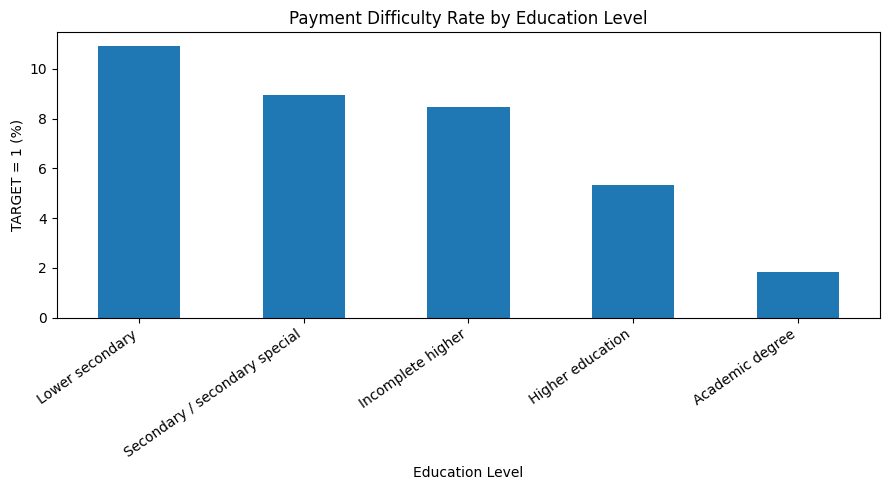

In [80]:
education_rate = (
    app_clean.groupby('NAME_EDUCATION_TYPE')['TARGET']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

education_rate.plot(kind='bar', figsize=(9, 5))

plt.title('Payment Difficulty Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## Analysis: Payment Difficulty Rate by Income Types

### Objective

To examine whether payment difficulty rates differ across applicant income types.

### Method

Applicants were categorise by income types, and the proportion of applicants with TARGET = 1 was calculated for each types.

In [81]:
# Number of clients by income and TARGET
print(pd.crosstab(
    app_clean['NAME_INCOME_TYPE'],
    app_clean['TARGET']
))

# TARGET percentage in each income category
print(
    pd.crosstab(
        app_clean['NAME_INCOME_TYPE'],
        app_clean['TARGET'],
        normalize='index'
    ).mul(100).round(2)
)

TARGET                     0      1
NAME_INCOME_TYPE                   
Businessman               10      0
Commercial associate   66257   5360
Maternity leave            3      2
Pensioner              52380   2982
State servant          20454   1249
Student                   18      0
Unemployed                14      8
Working               143550  15224
TARGET                     0      1
NAME_INCOME_TYPE                   
Businessman           100.00   0.00
Commercial associate   92.52   7.48
Maternity leave        60.00  40.00
Pensioner              94.61   5.39
State servant          94.25   5.75
Student               100.00   0.00
Unemployed             63.64  36.36
Working                90.41   9.59


### Results and Interpretation : Income Type vs Payment Difficulties

The analysis shows that payment difficulty rates vary across income types. The `Working` category has the largest number of customers with `TARGET = 1` (15,224) and an observed rate of 9.59%. `Pensioner` and `State servant` have lower observed rates of 5.39% and 5.75%, respectively.

`Unemployed` and `Maternity leave` show higher observed rates of 36.36% and 40.00%. However, these categories contain only 22 and 5 customers, respectively, so their rates should be interpreted cautiously. Similarly, the absence of `TARGET = 1` cases among `Businessman` and `Student` does not establish zero underlying risk because their sample sizes are small.

Overall, income type is associated with differences in observed payment difficulty rates in this dataset, but these descriptive results do not establish causation.

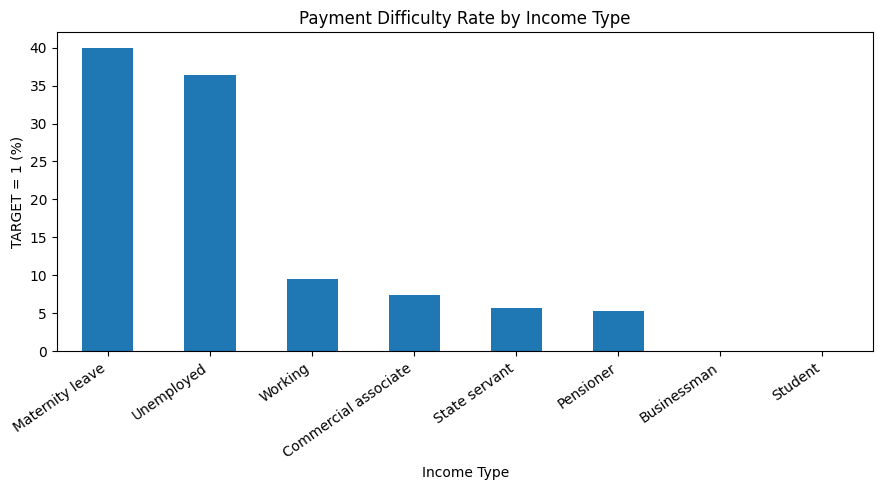

In [82]:
income_rate = (
    app_clean.groupby('NAME_INCOME_TYPE')['TARGET']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

income_rate.plot(kind='bar', figsize=(9, 5))

plt.title('Payment Difficulty Rate by Income Type')
plt.xlabel('Income Type')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## Analysis: Payment Difficulty Rate by Occupation

### Objective

To examine whether payment difficulty rates differ across applicant Occupations.

### Method

Applicants were categorise by occupations, and the proportion of applicants with TARGET = 1 was calculated for each types.

In [83]:
# Number of clients by occupation and TARGET
print(pd.crosstab(
    app_clean['OCCUPATION_TYPE'],
    app_clean['TARGET']
))

# TARGET percentage in each income category
print(
    pd.crosstab(
        app_clean['OCCUPATION_TYPE'],
        app_clean['TARGET'],
        normalize='index'
    ).mul(100).round(2)
)

TARGET                     0     1
OCCUPATION_TYPE                   
Accountants             9339   474
Cleaning staff          4206   447
Cooking staff           5325   621
Core staff             25832  1738
Drivers                16496  2107
HR staff                 527    36
High skill tech staff  10679   701
IT staff                 492    34
Laborers               49348  5838
Low-skill Laborers      1734   359
Managers               20043  1328
Medicine staff          7965   572
Private service staff   2477   175
Realty agents            692    59
Sales staff            29010  3092
Secretaries             1213    92
Security staff          5999   722
Waiters/barmen staff    1196   152
TARGET                     0      1
OCCUPATION_TYPE                    
Accountants            95.17   4.83
Cleaning staff         90.39   9.61
Cooking staff          89.56  10.44
Core staff             93.70   6.30
Drivers                88.67  11.33
HR staff               93.61   6.39
High skill t

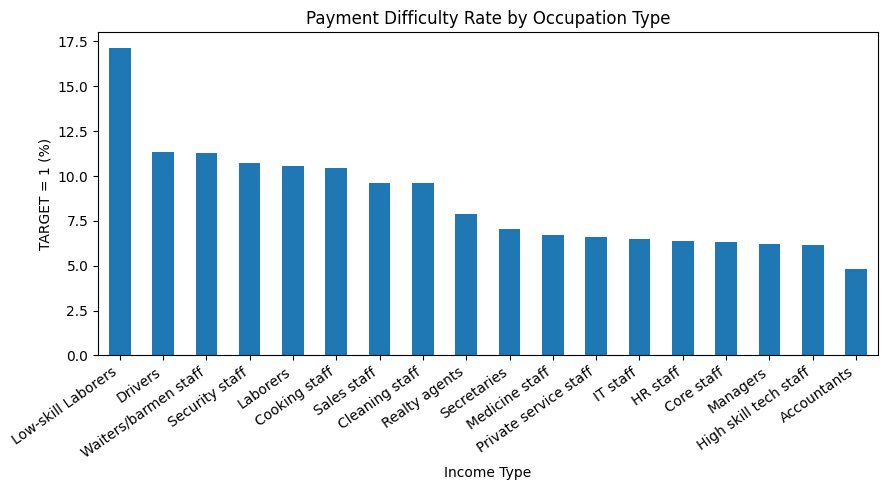

In [84]:
occupation_rate = (
    app_clean.groupby('OCCUPATION_TYPE')['TARGET']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

occupation_rate.plot(kind='bar', figsize=(9, 5))

plt.title('Payment Difficulty Rate by Occupation Type')
plt.xlabel('Income Type')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

### Results & Interpretation : Occupation Type vs Payment Difficulties

The analysis shows that payment difficulty rates vary across occupation categories. `Low-skill Laborers` recorded the highest observed rate of `TARGET = 1` at 17.15% (359 out of 2,093 customers). This was followed by `Drivers` at 11.33%, `Waiters/barmen staff` at 11.28%, and `Security staff` at 10.74%.

In terms of the number of customers experiencing payment difficulties, `Laborers` recorded the highest count at 5,838, with a rate of 10.58%. In contrast, `Accountants` had a lower observed rate of 4.83%.

These findings indicate an association between occupation category and payment difficulty rates in the dataset. However, the results are descriptive and do not establish that occupation causes payment difficulties. Other factors, such as income and credit amount, may also contribute to the observed differences.

## Analysis: Payment Difficulty Rate by Family Status

### Objective

To examine whether payment difficulty rates differ across applicant family status.

### Method

Applicants were categorise by family status, and the proportion of applicants with TARGET = 1 was calculated for each status.

In [85]:
# Number of clients by family status and TARGET
print(pd.crosstab(
    app_clean['NAME_FAMILY_STATUS'],
    app_clean['TARGET']
))

# TARGET percentage in each income category
print(
    pd.crosstab(
        app_clean['NAME_FAMILY_STATUS'],
        app_clean['TARGET'],
        normalize='index'
    ).mul(100).round(2)
)

TARGET                     0      1
NAME_FAMILY_STATUS                 
Civil marriage         26814   2961
Married               181582  14850
Separated              18150   1620
Single / not married   40987   4457
Unknown                    2      0
Widow                  15151    937
TARGET                     0     1
NAME_FAMILY_STATUS                
Civil marriage         90.06  9.94
Married                92.44  7.56
Separated              91.81  8.19
Single / not married   90.19  9.81
Unknown               100.00  0.00
Widow                  94.18  5.82


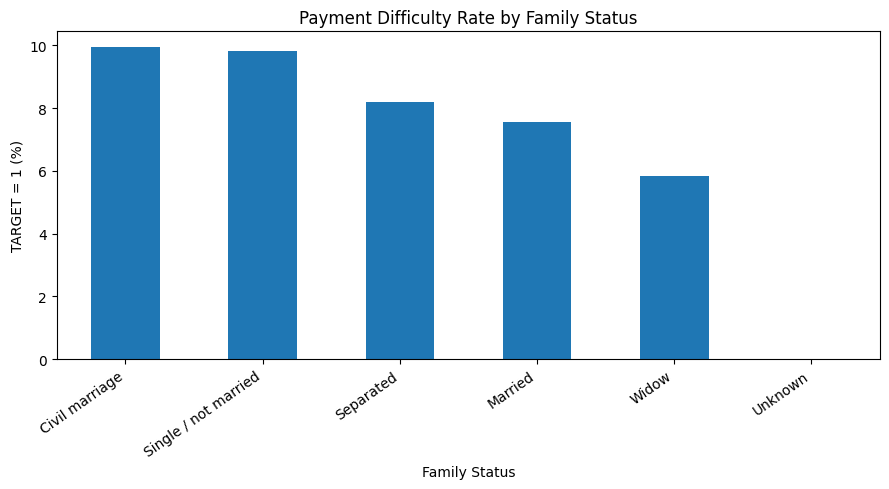

In [86]:
Family_status_rate = (
    app_clean.groupby('NAME_FAMILY_STATUS')['TARGET']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

Family_status_rate.plot(kind='bar', figsize=(9, 5))

plt.title('Payment Difficulty Rate by Family Status')
plt.xlabel('Family Status')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

### Results & Interpretation : Family Status vs Payment Difficulties

The analysis reveals differences in payment difficulty rates across family status categories. `Civil marriage` recorded the highest observed rate of `TARGET = 1` at 9.94%, followed closely by `Single / not married` at 9.81%. `Separated` customers had a rate of 8.19%, while `Married` customers recorded 7.56%.

Although `Married` customers had the largest number of payment difficulty cases (14,850), this category also contained the largest number of customers overall. Therefore, the raw number of cases should not be interpreted as indicating the highest risk rate. `Widow` customers recorded a lower rate of 5.82%. The `Unknown` category contained only two customers, so its observed rate is not meaningful for general comparison.

Overall, payment difficulty rates differ across family status categories in this dataset. These descriptive findings indicate an association, not a causal relationship.

## Summary

**1. Education**
The highest TARGET = 1 rate is Lower secondary (10.93%), but this category is smaller compared to Secondary / secondary special.

**2. Income type**
The 'Working' category has the highest number of cases (15,224) and a rate of 9.59%. High rates within smaller categories, such as 'Maternity leave', should be interpreted with caution.

**3.Occupation**
Low-skill laborers recorded the highest rate for TARGET = 1, at 17.15%. Meanwhile, the 'Laborers' category had the highest number of cases.

**4. Family status**
Civil marriage (9.94%) and Single/not married (9.81%) recorded higher rates compared to Married (7.56%).

# 05. Segmented Univariate Analysis

## Numeric: age, income, credit, annuity

## Analysis: Payment Difficulty Rate by Age Group

### Objective

To examine whether payment difficulty rates differ across applicant age groups.

### Method

Applicants age in days is converted to age in years before grouped by age, and the proportion of applicants with TARGET = 1 and TARGET = 0 was calculated for each group.

In [87]:
# Applicants age in days is converted to age in years before grouped by age
app_clean['AGE_YEARS'] = (
    app_clean['DAYS_BIRTH'].abs() / 365.25
).round(1)

# Check the result
print(app_clean[['DAYS_BIRTH', 'AGE_YEARS']].head())

   DAYS_BIRTH  AGE_YEARS
0       -9461       25.9
1      -16765       45.9
2      -19046       52.1
3      -19005       52.0
4      -19932       54.6


In [88]:
# Descriptive statistics for each TARGET group
age_summary = app_clean.groupby('TARGET')['AGE_YEARS'].describe()

print(age_summary.round(2))

           count   mean    std   min   25%   50%   75%   max
TARGET                                                      
0       282686.0  44.18  11.95  20.5  34.3  43.5  54.2  69.1
1        24825.0  40.75  11.48  21.0  31.2  39.1  49.4  68.9


In [89]:
age_comparison = app_clean.groupby('TARGET')['AGE_YEARS'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

print(age_comparison)

         count   mean  median    std
TARGET                              
0       282686  44.18    43.5  11.95
1        24825  40.75    39.1  11.48


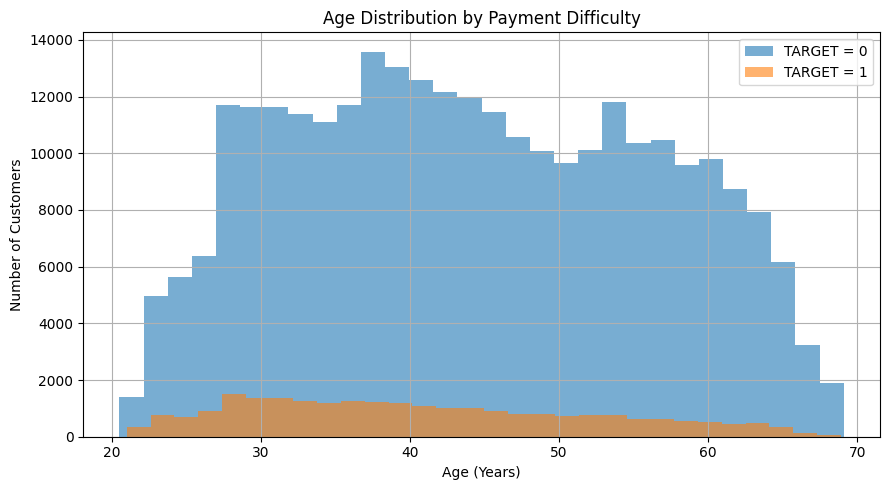

In [90]:
plt.figure(figsize=(9, 5))

app_clean.loc[
    app_clean['TARGET'] == 0, 'AGE_YEARS'
].hist(bins=30, alpha=0.6, label='TARGET = 0')

app_clean.loc[
    app_clean['TARGET'] == 1, 'AGE_YEARS'
].hist(bins=30, alpha=0.6, label='TARGET = 1')

plt.title('Age Distribution by Payment Difficulty')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Customers')
plt.legend()
plt.tight_layout()
plt.show()

### Results & Interpretation : Age vs Payment Difficulties

The analysis indicates that customers experiencing payment difficulties tend to be younger than those without recorded payment difficulties. Customers with `TARGET = 1` have a mean age of 40.75 years and a median age of 39.1 years, compared with a mean of 44.18 years and a median of 43.5 years for customers with `TARGET = 0`.

This represents a difference of approximately 3.43 years in mean age between the two groups. Although their age distributions overlap, the descriptive statistics suggest an association between customer age and payment difficulties in this dataset. Further analysis is needed to determine how payment difficulty rates vary across age groups. These findings do not establish that younger age causes payment difficulties.

## Analysis: Payment Difficulty Rate (TARGET = 1) by Age Group

### Objective
To examine whether applicants with payment difficulties differ across applicant age groups.

### Method
Applicants were grouped by age, and the proportion of applicants with TARGET = 1 was calculated for each group.

In [91]:
# Group customers by age
age_bins = [20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70]
age_labels = [
    '20–24', '25–29', '30–34', '35–39', '40–44',
    '45–49', '50–54', '55–59', '60–64', '65–69'
]

app_clean['AGE_GROUP'] = pd.cut(
    app_clean['AGE_YEARS'],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Calculate customer count and payment difficulty rate
age_risk = app_clean.groupby(
    'AGE_GROUP', observed=False
).agg(
    Customer_Count=('TARGET', 'size'),
    Target_1_Count=('TARGET', 'sum'),
    Payment_Difficulty_Rate=('TARGET', 'mean')
)

age_risk['Payment_Difficulty_Rate'] *= 100

print(age_risk.round(2))

           Customer_Count  Target_1_Count  Payment_Difficulty_Rate
AGE_GROUP                                                         
20–24               11993            1481                    12.35
25–29               32745            3651                    11.15
30–34               39522            4067                    10.29
35–39               42868            3824                     8.92
40–44               41442            3261                     7.87
45–49               35160            2603                     7.40
50–54               34949            2349                     6.72
55–59               33167            1835                     5.53
60–64               27505            1449                     5.27
65–69                8160             305                     3.74


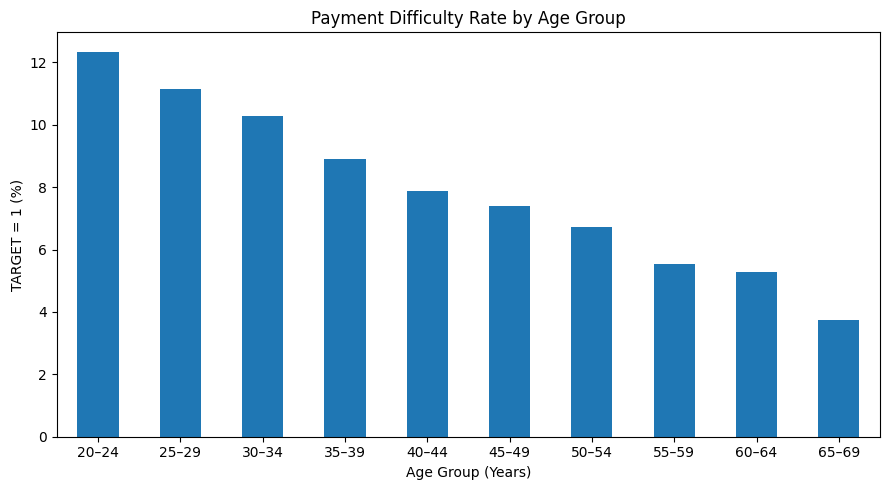

In [92]:
age_risk['Payment_Difficulty_Rate'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Payment Difficulty Rate by Age Group')
plt.xlabel('Age Group (Years)')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Age Group vs Payment Difficulties

The analysis reveals a decreasing trend in payment difficulty rates across older age groups. Customers aged 20–24 recorded the highest rate of `TARGET = 1` at 12.35% (1,481 out of 11,993 customers). The rate declined to 11.15% for ages 25–29 and 10.29% for ages 30–34.

In comparison, customers aged 65–69 recorded the lowest observed rate at 3.74% (305 out of 8,160 customers). The difference between the youngest and oldest age groups was 8.61 percentage points.

Overall, the results indicate an association between age group and payment difficulty rates in this dataset, with younger groups showing higher observed rates. However, this descriptive analysis does not establish that age causes payment difficulties, and other factors may contribute to the pattern.

## Analysis: Payment Difficulty Rate by Income Group

### Objective

To examine whether payment difficulty rates differ across applicant income groups.

### Method

Applicants were grouped by income, and the proportion of applicants with TARGET = 1 was calculated for each group.

In [93]:
# Descriptive statistics for income by TARGET
income_summary = app_clean.groupby('TARGET')['AMT_INCOME_TOTAL'].describe()

print(income_summary.round(2))

           count       mean        std      min       25%       50%       75%  \
TARGET                                                                          
0       282686.0  169077.72  110476.27  25650.0  112500.0  148500.0  202500.0   
1        24825.0  165611.76  746676.96  25650.0  112500.0  135000.0  202500.0   

                max  
TARGET               
0        18000090.0  
1       117000000.0  


In [94]:
# Compare mean and median income by TARGET
income_comparison = app_clean.groupby('TARGET')['AMT_INCOME_TOTAL'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

print(income_comparison)

         count       mean    median        std      min          max
TARGET                                                              
0       282686  169077.72  148500.0  110476.27  25650.0   18000090.0
1        24825  165611.76  135000.0  746676.96  25650.0  117000000.0


In [95]:
# Divide customers into four income groups
app_clean['INCOME_GROUP'] = pd.qcut(
    app_clean['AMT_INCOME_TOTAL'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

In [96]:
# Step 2: Calculate payment difficulty rate
income_risk = app_clean.groupby(
    'INCOME_GROUP',
    observed=False
).agg(
    Customer_Count=('TARGET', 'size'),
    Target_1_Count=('TARGET', 'sum'),
    Payment_Difficulty_Rate=('TARGET', 'mean')
)

income_risk['Payment_Difficulty_Rate'] *= 100

In [97]:
# Step 3: Display the results
print(income_risk.round(2))

                   Customer_Count  Target_1_Count  Payment_Difficulty_Rate
INCOME_GROUP                                                              
Q1 - Lowest                100578            8443                     8.39
Q2 - Lower-middle           53182            4537                     8.53
Q3 - Upper-middle           82213            6902                     8.40
Q4 - Highest                71538            4943                     6.91


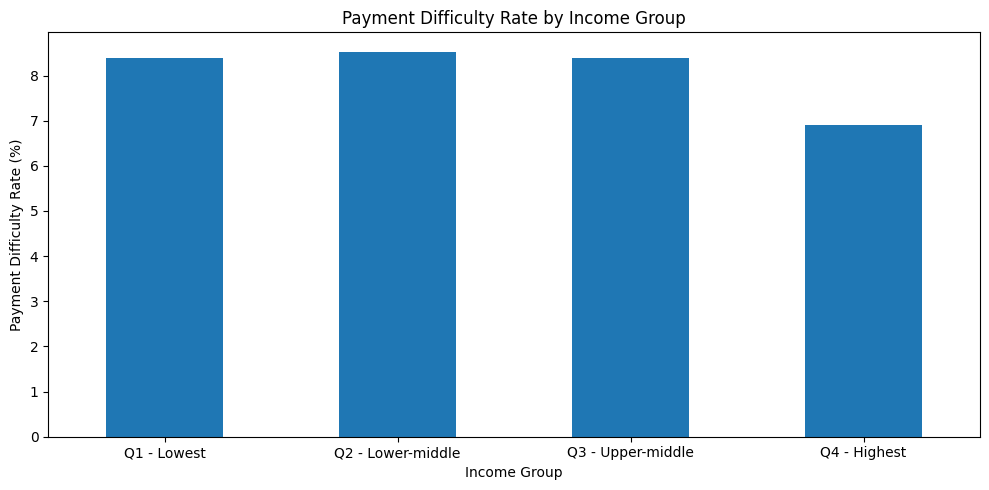

In [98]:
income_rate = income_risk['Payment_Difficulty_Rate']

income_rate.plot(kind='bar', figsize=(10, 5))

plt.title('Payment Difficulty Rate by Income Group')
plt.xlabel('Income Group')
plt.ylabel('Payment Difficulty Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [99]:
# Check income quartile boundaries
print(app_clean['AMT_INCOME_TOTAL'].quantile([0, 0.25, 0.50, 0.75, 1.00]))

0.00        25650.0
0.25       112500.0
0.50       147150.0
0.75       202500.0
1.00    117000000.0
Name: AMT_INCOME_TOTAL, dtype: float64


### Income Group vs Payment Difficulties

The analysis shows that payment difficulty rates vary across income groups, but the pattern is not consistently decreasing as income increases. The `Q2 - Lower-middle` group recorded the highest observed rate of `TARGET = 1` at 8.53%, followed closely by `Q3 - Upper-middle` at 8.40% and `Q1 - Lowest` at 8.39%.

The `Q4 - Highest` group had the lowest observed rate at 6.91%, a difference of 1.62 percentage points compared with the highest-rate group. These results suggest that the highest-income group has a lower observed payment difficulty rate, while the other three groups show relatively similar rates.

The findings indicate an association between income grouping and payment difficulty rates, but they do not establish causation. The income groups also differ in size, so the grouping method and distribution of income should be considered when interpreting the results.

## Analysis: Payment Difficulty Rate by Credit Amount

### Objective

To examine whether payment difficulty rates differ across applicant credit amount.

### Method

Applicants were grouped by credit amount, and the proportion of applicants with TARGET = 1 was calculated for each group.

In [100]:
# Descriptive statistics for credit amount by TARGET
credit_summary = app_clean.groupby('TARGET')['AMT_CREDIT'].describe()

print(credit_summary.round(2))

           count       mean        std      min       25%       50%       75%  \
TARGET                                                                          
0       282686.0  602648.28  406845.91  45000.0  270000.0  517788.0  810000.0   
1        24825.0  557778.53  346433.24  45000.0  284400.0  497520.0  733315.5   

              max  
TARGET             
0       4050000.0  
1       4027680.0  


In [101]:
credit_comparison = app_clean.groupby('TARGET')['AMT_CREDIT'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

print(credit_comparison)

         count       mean    median        std      min        max
TARGET                                                            
0       282686  602648.28  517788.0  406845.91  45000.0  4050000.0
1        24825  557778.53  497520.0  346433.24  45000.0  4027680.0


### Credit Amount vs Payment Difficulties

The descriptive analysis shows that customers with `TARGET = 1` have a lower mean credit amount of 557,778.53 compared with 602,648.28 for customers with `TARGET = 0`. The median credit amount is also lower for the payment-difficulty group, at 497,520 versus 517,788.

However, the first quartile is higher for `TARGET = 1`, while the third quartile is lower. This indicates differences in the distributions of credit amounts between the two groups. The maximum credit amounts are relatively similar.

Overall, the results show an association between credit amount distributions and payment difficulty status, but the descriptive statistics alone do not establish that credit amount causes payment difficulties.

In [102]:
# Divide customers into credit amount quartiles
app_clean['CREDIT_GROUP'] = pd.qcut(
    app_clean['AMT_CREDIT'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

# Calculate payment difficulty rate by credit group
credit_risk = app_clean.groupby(
    'CREDIT_GROUP',
    observed=False
).agg(
    Customer_Count=('TARGET', 'size'),
    Target_1_Count=('TARGET', 'sum'),
    Payment_Difficulty_Rate=('TARGET', 'mean')
)

credit_risk['Payment_Difficulty_Rate'] *= 100

print(credit_risk.round(2))

                   Customer_Count  Target_1_Count  Payment_Difficulty_Rate
CREDIT_GROUP                                                              
Q1 - Lowest                 78421            5680                     7.24
Q2 - Lower-middle           75428            7304                     9.68
Q3 - Upper-middle           77786            7126                     9.16
Q4 - Highest                75876            4715                     6.21


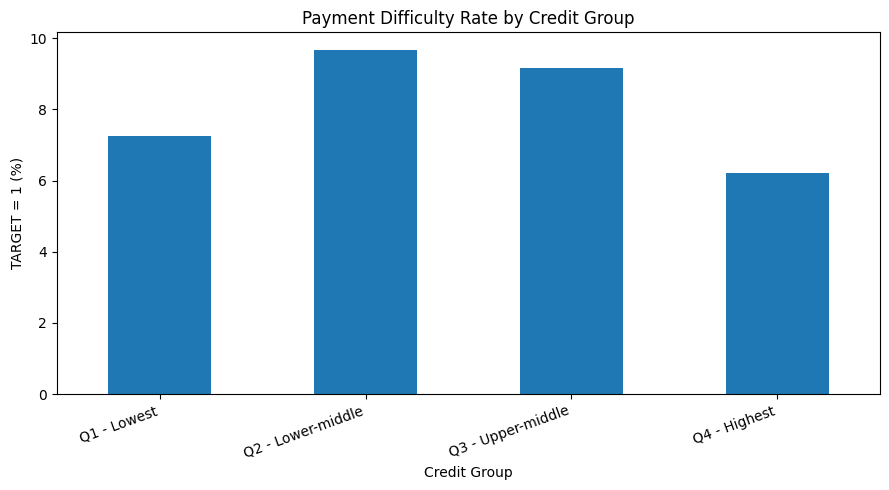

In [103]:
credit_risk['Payment_Difficulty_Rate'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Payment Difficulty Rate by Credit Group')
plt.xlabel('Credit Group')
plt.ylabel('TARGET = 1 (%)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### Credit Amount Group vs Payment Difficulties

The analysis reveals a non-linear pattern between credit amount groups and payment difficulty rates. The `Q2 - Lower-middle` group recorded the highest `TARGET = 1` rate at 9.68%, followed by `Q3 - Upper-middle` at 9.16%. The `Q1 - Lowest` group had a rate of 7.24%, while the `Q4 - Highest` group recorded the lowest rate at 6.21%.

The difference between the highest and lowest observed rates was 3.47 percentage points. These findings suggest that customers in the middle credit amount groups had higher observed payment difficulty rates than those in the highest credit group.

However, this descriptive analysis does not establish that credit amount causes payment difficulties. Other variables, including income, age, and loan characteristics, may also be associated with the observed pattern.

## Analysis: Payment Difficulty Rate by Annuity Amount Group

### Objective

To examine whether payment difficulty rates differ across applicant Annuity Amount groups.

### Method

Applicants were grouped by Annuity amount, and the proportion of applicants with TARGET = 1 was calculated for each group.

In [104]:
# Descriptive statistics for annuity by TARGET
annuity_summary = app_clean.groupby('TARGET')['AMT_ANNUITY'].describe()

print(annuity_summary.round(2))

           count      mean       std     min      25%      50%      75%  \
TARGET                                                                    
0       282674.0  27163.62  14658.31  1615.5  16456.5  24876.0  34749.0   
1        24825.0  26481.74  12450.68  2722.5  17361.0  25263.0  32976.0   

             max  
TARGET            
0       258025.5  
1       149211.0  


In [105]:
annuity_comparison = app_clean.groupby('TARGET')['AMT_ANNUITY'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

print(annuity_comparison)

         count      mean   median       std     min       max
TARGET                                                       
0       282674  27163.62  24876.0  14658.31  1615.5  258025.5
1        24825  26481.74  25263.0  12450.68  2722.5  149211.0


In [106]:
app_clean['ANNUITY_GROUP'] = pd.qcut(
    app_clean['AMT_ANNUITY'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

annuity_target = pd.crosstab(
    app_clean['ANNUITY_GROUP'],
    app_clean['TARGET']
)

annuity_rate = pd.crosstab(
    app_clean['ANNUITY_GROUP'],
    app_clean['TARGET'],
    normalize='index'
) * 100

annuity_result = annuity_target.copy()
annuity_result['Total'] = annuity_target.sum(axis=1)
annuity_result['TARGET_1_Rate_%'] = annuity_rate[1].round(2)

print(annuity_result)

TARGET                 0     1  Total  TARGET_1_Rate_%
ANNUITY_GROUP                                         
Q1 - Lowest        71463  5430  76893             7.06
Q2 - Lower-middle  70150  6730  76880             8.75
Q3 - Upper-middle  69857  7105  76962             9.23
Q4 - Highest       71204  5560  76764             7.24


### Annuity Amount Group vs Payment Difficulties

The analysis reveals a non-linear relationship between annuity amount groups and payment difficulty rates. The `Q3 - Upper-middle` group recorded the highest observed `TARGET = 1` rate at 9.23% (7,105 out of 76,962 customers), followed by `Q2 - Lower-middle` at 8.75%.

In contrast, the `Q1 - Lowest` group recorded the lowest rate at 7.06%, while the `Q4 - Highest` group had a rate of 7.24%. The difference between the highest and lowest observed rates was 2.17 percentage points.

These findings suggest that customers in the middle annuity amount groups had higher observed payment difficulty rates than those in the lowest and highest groups. However, this descriptive analysis does not establish causation. Other factors, such as income, credit amount, and customer characteristics, may also be associated with the observed pattern.

## Analysis: Payment Difficulty Rate by Goods Price

### Objective

To examine whether payment difficulty rates differ across applicant age groups.

## Method

Applicants were grouped by age, and the proportion of applicants with TARGET = 1 was calculated for each group.

In [107]:
goods_summary = app_clean.groupby('TARGET')['AMT_GOODS_PRICE'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

print(goods_summary)

         count       mean    median        std      min        max
TARGET                                                            
0       282429  542736.80  450000.0  373785.49  40500.0  4050000.0
1        24804  488972.41  450000.0  311636.50  45000.0  3600000.0


### Goods Price vs Payment Difficulties

The descriptive analysis shows that customers with `TARGET = 1` had a lower mean goods price of 488,972.41 compared with 542,736.80 for customers with `TARGET = 0`. However, both groups recorded the same median goods price of 450,000.

The standard deviation was also lower for customers with `TARGET = 1`, indicating less variability in goods prices within this group. The maximum goods price was 3,600,000 for `TARGET = 1`, compared with 4,050,000 for `TARGET = 0`.

Although the mean goods price differed between the two groups, these summary statistics alone do not establish a relationship between goods price and payment difficulty risk. Further analysis of payment difficulty rates across goods price groups is required to examine this pattern.

In [108]:
app_clean['GOODS_PRICE_GROUP'] = pd.qcut(
    app_clean['AMT_GOODS_PRICE'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

goods_target = pd.crosstab(
    app_clean['GOODS_PRICE_GROUP'],
    app_clean['TARGET']
)

goods_rate = pd.crosstab(
    app_clean['GOODS_PRICE_GROUP'],
    app_clean['TARGET'],
    normalize='index'
) * 100

goods_result = goods_target.copy()
goods_result['Total'] = goods_target.sum(axis=1)
goods_result['TARGET_1_Rate_%'] = goods_rate[1].round(2)

print(goods_result)

TARGET                 0     1  Total  TARGET_1_Rate_%
GOODS_PRICE_GROUP                                     
Q1 - Lowest        73509  6368  79877             7.97
Q2 - Lower-middle  69567  8535  78102            10.93
Q3 - Upper-middle  68208  5512  73720             7.48
Q4 - Highest       71145  4389  75534             5.81


### Goods Price Group vs Payment Difficulties

The analysis reveals a non-linear pattern in payment difficulty rates across goods price groups. The `Q2 - Lower-middle` group recorded the highest observed `TARGET = 1` rate at 10.93% (8,535 out of 78,102 customers). This was followed by `Q1 - Lowest` at 7.97% and `Q3 - Upper-middle` at 7.48%.

In contrast, the `Q4 - Highest` group recorded the lowest observed rate at 5.81%. The difference between the highest and lowest rates was 5.12 percentage points.

These findings indicate that customers in the lower-middle goods price group had a higher observed payment difficulty rate, while those in the highest goods price group had a lower rate. However, this descriptive analysis does not establish causation. Other factors, such as income, credit amount, and customer characteristics, may contribute to the observed differences.

# 06. Bivariate & Multivariate Analysis

## Analysis : Income vs credit

### Objective

The objective of this analysis is to examine the relationship between applicants' income and credit amount, and determine whether the relationship differs between applicants with and without payment difficulties.

### Method

Pearson and Spearman correlation coefficients are used to examine the relationship between AMT_INCOME_TOTAL and AMT_CREDIT for TARGET 0 and TARGET 1 separately.

In [109]:
income_credit_summary = app_clean.groupby('TARGET').agg(
    Income_Median=('AMT_INCOME_TOTAL', 'median'),
    Income_Mean=('AMT_INCOME_TOTAL', 'mean'),
    Credit_Median=('AMT_CREDIT', 'median'),
    Credit_Mean=('AMT_CREDIT', 'mean'),
    Customer_Count=('TARGET', 'count')
)

print(income_credit_summary.round(2))

        Income_Median  Income_Mean  Credit_Median  Credit_Mean  Customer_Count
TARGET                                                                        
0            148500.0    169077.72       517788.0    602648.28          282686
1            135000.0    165611.76       497520.0    557778.53           24825


In [110]:
income_credit_corr = app_clean.groupby('TARGET').apply(
    lambda group: group[
        ['AMT_INCOME_TOTAL', 'AMT_CREDIT']
    ].corr().iloc[0, 1],
    include_groups=False
)

print(income_credit_corr)

TARGET
0    0.342799
1    0.038131
dtype: float64


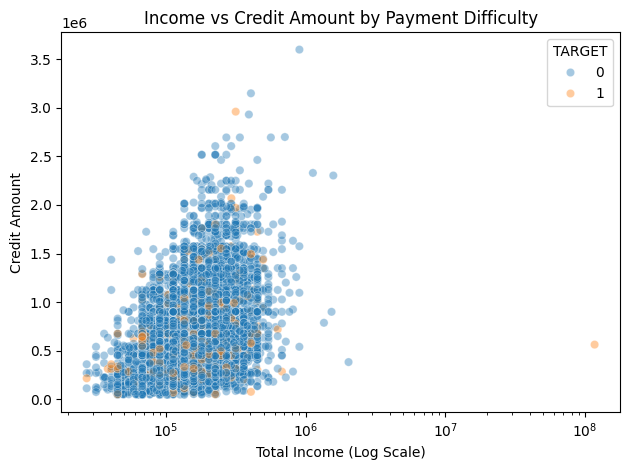

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns

sample = app_clean.sample(
    n=10000,
    random_state=42
)

sns.scatterplot(
    data=sample,
    x='AMT_INCOME_TOTAL',
    y='AMT_CREDIT',
    hue='TARGET',
    alpha=0.4
)

plt.xscale('log')
plt.title('Income vs Credit Amount by Payment Difficulty')
plt.xlabel('Total Income (Log Scale)')
plt.ylabel('Credit Amount')
plt.tight_layout()
plt.show()

In [112]:
for target_value in [0, 1]:
    subset = app_clean.loc[
        app_clean['TARGET'] == target_value,
        ['AMT_INCOME_TOTAL', 'AMT_CREDIT']
    ]

    pearson = subset.corr(method='pearson').iloc[0, 1]
    spearman = subset.corr(method='spearman').iloc[0, 1]

    print(f"TARGET = {target_value}")
    print(f"Pearson : {pearson:.4f}")
    print(f"Spearman: {spearman:.4f}")
    print()

TARGET = 0
Pearson : 0.3428
Spearman: 0.4160

TARGET = 1
Pearson : 0.0381
Spearman: 0.3593



### Income vs Credit Amount by Payment Difficulty

The analysis examined the relationship between total income and credit amount separately for customers with and without recorded payment difficulties.

For customers with `TARGET = 0`, Pearson's correlation was 0.3428, while Spearman's correlation was 0.4160, indicating a positive association between income and credit amount.

For customers with `TARGET = 1`, Pearson's correlation was much weaker at 0.0381, whereas Spearman's correlation was 0.3593. This difference suggests that the relationship in this group may not be adequately described by a linear correlation measure alone.

The scatter plot shows considerable overlap between the two target groups, with no clear visual separation based on income and credit amount alone. Extreme income values may also influence the correlation results.

Overall, the findings suggest a positive monotonic association between income and credit amount in both groups, particularly according to Spearman's correlation. However, these results do not establish causation or demonstrate that income and credit amount alone can distinguish customers who experience payment difficulties.

## Age vs Credit Amount by Payment Difficulty

### Objective

The objective of this analysis is to examine the relationship between applicants' age and credit amount, and determine whether the relationship differs between applicants with and without payment difficulties.

Method

Pearson and Spearman correlation coefficients are used to examine the relationship between AGE_YEARS and AMT_CREDIT for TARGET 0 and TARGET 1 separately.

In [113]:
for target_value in [0, 1]:
    subset = app_clean.loc[
        app_clean['TARGET'] == target_value,
        ['AGE_YEARS', 'AMT_CREDIT']
    ]

    pearson = subset.corr(method='pearson').iloc[0, 1]
    spearman = subset.corr(method='spearman').iloc[0, 1]

    print(f"TARGET = {target_value}")
    print(f"Pearson : {pearson:.4f}")
    print(f"Spearman: {spearman:.4f}")
    print()

TARGET = 0
Pearson : 0.0474
Spearman: 0.0571

TARGET = 1
Pearson : 0.1353
Spearman: 0.1552



### Age vs Credit Amount by Payment Difficulty

The analysis shows a weak positive association between customer age and credit amount in both target groups. For customers with `TARGET = 0`, Pearson's correlation was 0.0474 and Spearman's correlation was 0.0571, indicating a very weak relationship.

For customers with `TARGET = 1`, Pearson's correlation was 0.1353 and Spearman's correlation was 0.1552. Although these values were higher than those observed for `TARGET = 0`, the association remained weak.

Overall, age and credit amount have only a limited monotonic and linear association within each target group. These findings do not establish causation and do not directly indicate how age or credit amount affects payment difficulty risk.

## AMT_CREDIT vs AMT_ANNUITY

### Objective

The objective of this analysis is to examine the relationship between applicants' annuity and credit amount, and determine whether the relationship differs between applicants with and without payment difficulties.

Method

Pearson and Spearman correlation coefficients are used to examine the relationship between AMT_ANNUITY and AMT_CREDIT for TARGET 0 and TARGET 1 separately.

In [114]:
for target_value in [0, 1]:
    subset = app_clean.loc[
        app_clean['TARGET'] == target_value,
        ['AMT_CREDIT', 'AMT_ANNUITY']
    ].dropna()

    pearson = subset.corr(method='pearson').iloc[0, 1]
    spearman = subset.corr(method='spearman').iloc[0, 1]

    print(f"TARGET = {target_value}")
    print(f"Pearson : {pearson:.4f}")
    print(f"Spearman: {spearman:.4f}")
    print()

TARGET = 0
Pearson : 0.7713
Spearman: 0.8319

TARGET = 1
Pearson : 0.7522
Spearman: 0.8114



### Credit Amount vs Annuity by Payment Difficulty

The analysis reveals a strong positive association between credit amount and annuity amount in both target groups. For customers with `TARGET = 0`, Pearson's correlation was 0.7713 and Spearman's correlation was 0.8319. For customers with `TARGET = 1`, the corresponding values were 0.7522 and 0.8114.

These results indicate that customers with higher credit amounts generally tend to have higher annuity amounts, regardless of their recorded payment difficulty status. The correlations were slightly stronger among customers with `TARGET = 0`, although the differences were small.

Overall, credit amount and annuity amount exhibit a strong positive association in this dataset. However, this relationship alone does not establish whether either variable independently predicts payment difficulties.

In [115]:
numeric_df = app_clean.select_dtypes(include='number')

target_corr = numeric_df.corr()['TARGET'].drop('TARGET')

target_corr = target_corr.sort_values(
    key=abs,
    ascending=False
)

print(target_corr.head(15).round(4))

EXT_SOURCE_3                  -0.1789
EXT_SOURCE_2                  -0.1605
EXT_SOURCE_1                  -0.1553
DAYS_BIRTH                     0.0782
AGE_YEARS                     -0.0782
REGION_RATING_CLIENT_W_CITY    0.0609
REGION_RATING_CLIENT           0.0589
DAYS_LAST_PHONE_CHANGE         0.0552
DAYS_ID_PUBLISH                0.0515
REG_CITY_NOT_WORK_CITY         0.0510
FLAG_EMP_PHONE                 0.0460
DAYS_EMPLOYED                 -0.0449
REG_CITY_NOT_LIVE_CITY         0.0444
FLAG_DOCUMENT_3                0.0443
FLOORSMAX_AVG                 -0.0440
Name: TARGET, dtype: float64


### Correlation Analysis: Numerical Features vs Payment Difficulty

The correlation analysis identified `EXT_SOURCE_3` (-0.1789), `EXT_SOURCE_2` (-0.1605), and `EXT_SOURCE_1` (-0.1553) as the numerical features with the strongest absolute Pearson correlations with `TARGET`.

All three features showed negative correlations, indicating that higher external source scores were associated with a lower likelihood of `TARGET = 1` in the observed data. However, the correlations were weak, suggesting that none of these features has a strong linear relationship with payment difficulty on its own.

`DAYS_BIRTH` had a positive correlation of 0.0782 with `TARGET`. Since this variable records birth dates as negative day counts, the positive correlation is consistent with younger customers tending to have higher observed payment difficulty rates.

The remaining features showed very weak correlations, with absolute values below 0.07. Overall, the results suggest that external source scores have the strongest linear associations with payment difficulty among the numerical features examined. Correlation does not establish causation, and the influence of missing values and other customer characteristics should be considered in further analysis.

In [116]:
#EXT_SOURCE_3 vs rate of payment difficulties
app_clean['EXT_SOURCE_3_GROUP'] = pd.qcut(
    app_clean['EXT_SOURCE_3'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

ext3_counts = pd.crosstab(
    app_clean['EXT_SOURCE_3_GROUP'],
    app_clean['TARGET']
)

ext3_rates = pd.crosstab(
    app_clean['EXT_SOURCE_3_GROUP'],
    app_clean['TARGET'],
    normalize='index'
) * 100

ext3_result = ext3_counts.copy()
ext3_result['Total'] = ext3_counts.sum(axis=1)
ext3_result['TARGET_1_Rate_%'] = ext3_rates[1].round(2)

print(ext3_result)

TARGET                  0     1  Total  TARGET_1_Rate_%
EXT_SOURCE_3_GROUP                                     
Q1 - Lowest         52659  9334  61993            15.06
Q2 - Lower-middle   56774  4610  61384             7.51
Q3 - Upper-middle   59123  3055  62178             4.91
Q4 - Highest        58842  2149  60991             3.52


In [117]:
app_clean['EXT_SOURCE_2_GROUP'] = pd.qcut(
    app_clean['EXT_SOURCE_2'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

ext2_counts = pd.crosstab(
    app_clean['EXT_SOURCE_2_GROUP'],
    app_clean['TARGET']
)

ext2_rates = pd.crosstab(
    app_clean['EXT_SOURCE_2_GROUP'],
    app_clean['TARGET'],
    normalize='index'
) * 100

ext2_result = ext2_counts.copy()
ext2_result['Total'] = ext2_counts.sum(axis=1)
ext2_result['TARGET_1_Rate_%'] = ext2_rates[1].round(2)

print(ext2_result)

TARGET                  0      1  Total  TARGET_1_Rate_%
EXT_SOURCE_2_GROUP                                      
Q1 - Lowest         65750  10966  76716            14.29
Q2 - Lower-middle   70439   6271  76710             8.17
Q3 - Upper-middle   72095   4618  76713             6.02
Q4 - Highest        73794   2918  76712             3.80


In [118]:
app_clean['EXT_SOURCE_1_GROUP'] = pd.qcut(
    app_clean['EXT_SOURCE_1'],
    q=4,
    labels=[
        'Q1 - Lowest',
        'Q2 - Lower-middle',
        'Q3 - Upper-middle',
        'Q4 - Highest'
    ]
)

ext1_counts = pd.crosstab(
    app_clean['EXT_SOURCE_1_GROUP'],
    app_clean['TARGET']
)

ext1_rates = pd.crosstab(
    app_clean['EXT_SOURCE_1_GROUP'],
    app_clean['TARGET'],
    normalize='index'
) * 100

ext1_result = ext1_counts.copy()
ext1_result['Total'] = ext1_counts.sum(axis=1)
ext1_result['TARGET_1_Rate_%'] = ext1_rates[1].round(2)

print(ext1_result)

TARGET                  0     1  Total  TARGET_1_Rate_%
EXT_SOURCE_1_GROUP                                     
Q1 - Lowest         28987  4547  33534            13.56
Q2 - Lower-middle   30928  2606  33534             7.77
Q3 - Upper-middle   31728  1804  33532             5.38
Q4 - Highest        32436  1097  33533             3.27


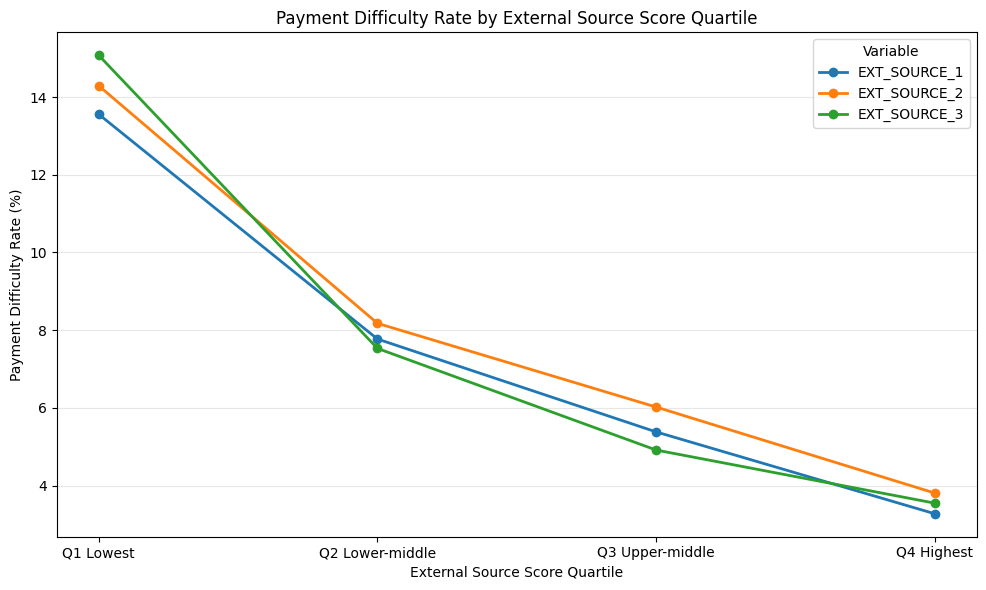

In [119]:
# External source scores to analyse
scores = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

quartile_labels = [
    'Q1 Lowest',
    'Q2 Lower-middle',
    'Q3 Upper-middle',
    'Q4 Highest'
]

fig, ax = plt.subplots(figsize=(10, 6))

for score in scores:
    # Exclude missing scores for this analysis
    temp = app_clean[['TARGET', score]].dropna().copy()

    # Divide scores into four approximately equal groups
    temp['Quartile'] = pd.qcut(
        temp[score].rank(method='first'),
        q=4,
        labels=quartile_labels
    )

    # Calculate payment difficulty rate in each quartile
    rates = temp.groupby(
        'Quartile', observed=False
    )['TARGET'].mean() * 100

    ax.plot(
        rates.index.astype(str),
        rates.values,
        marker='o',
        linewidth=2,
        label=score
    )

ax.set_title(
    'Payment Difficulty Rate by External Source Score Quartile'
)
ax.set_xlabel('External Source Score Quartile')
ax.set_ylabel('Payment Difficulty Rate (%)')
ax.legend(title='Variable')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(
    'rq2_external_source_scores.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


### External Source Scores vs Payment Difficulties

The analysis reveals a consistent decreasing trend in payment difficulty rates across the quartile groups of all three external source scores.

For `EXT_SOURCE_1`, the payment difficulty rate decreased from 13.56% in the lowest-score group to 3.27% in the highest-score group, a difference of 10.29 percentage points.

Similarly, `EXT_SOURCE_2` showed a decrease from 14.29% to 3.80%, while `EXT_SOURCE_3` decreased from 15.06% to 3.52%. These patterns are consistent with the negative Pearson correlations observed between the external source scores and `TARGET`.

Overall, customers in the lowest external source score groups had substantially higher observed payment difficulty rates than those in the highest-score groups. These findings suggest that external source scores are useful features for further risk analysis. However, the results are descriptive, do not establish causation, and do not independently demonstrate predictive performance.

### Analysis of previous application history


In [120]:
# Count contract status from previous_application.csv
prev_clean['NAME_CONTRACT_STATUS'].value_counts()

,count
NAME_CONTRACT_STATUS,
Approved,1036781
Canceled,316319
Refused,290678
Unused offer,26436


In [121]:
# contract status by percentage from previous_application.csv
prev_clean['NAME_CONTRACT_STATUS'].value_counts(normalize=True).mul(100).round(2)

,proportion
NAME_CONTRACT_STATUS,
Approved,62.07
Canceled,18.94
Refused,17.40
Unused offer,1.58


In [122]:
# Count contract type by status
pd.crosstab(
    prev_clean['NAME_CONTRACT_TYPE'],
    prev_clean['NAME_CONTRACT_STATUS']
)

NAME_CONTRACT_STATUS,Approved,Canceled,Refused,Unused offer
NAME_CONTRACT_TYPE,,,,
Cash loans,312540,268591,165928,494
Consumer loans,626470,1559,75185,25937
Revolving loans,97771,45854,49534,5
XNA,0,315,31,0


In [123]:
# contract type percentage by status
pd.crosstab(
    prev_clean['NAME_CONTRACT_TYPE'],
    prev_clean['NAME_CONTRACT_STATUS'],
    normalize='index'
).mul(100).round(2)

NAME_CONTRACT_STATUS,Approved,Canceled,Refused,Unused offer
NAME_CONTRACT_TYPE,,,,
Cash loans,41.81,35.93,22.20,0.07
Consumer loans,85.92,0.21,10.31,3.56
Revolving loans,50.62,23.74,25.64,0.00
XNA,0.00,91.04,8.96,0.00


In [124]:
prev_count = (
    prev_clean.groupby('SK_ID_CURR')['SK_ID_PREV']
    .count()
)

prev_count.describe()

,SK_ID_PREV
count,338857.000000
mean,4.928964
std,4.220716
min,1.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,77.000000


In [125]:
prev_count.value_counts().sort_index().head(15)

,count
SK_ID_PREV,
1,60458
2,52737
3,45966
4,38159
5,30886
6,24588
7,19216
8,15085
9,11627


In [126]:
#combine data from app_clean and prev_clean
prev_count = (
    prev_clean.groupby('SK_ID_CURR')['SK_ID_PREV']
    .count()
    .reset_index(name='PREV_APP_COUNT')
)

app_prev = app_clean.merge(
    prev_count,
    on='SK_ID_CURR',
    how='left'
)

app_prev['PREV_APP_COUNT'] = (
    app_prev['PREV_APP_COUNT'].fillna(0)
)

In [127]:
#Compare averages by TARGET
app_prev.groupby('TARGET')['PREV_APP_COUNT'].agg(
    ['count', 'mean', 'median']
).round(2)

,count,mean,median
TARGET,,,
0,282686,4.57,3.0
1,24825,4.93,4.0


In [128]:
#Payment difficulty rate by number of applications
app_prev['PREV_APP_GROUP'] = pd.cut(
    app_prev['PREV_APP_COUNT'],
    bins=[-1, 0, 2, 5, 10, float('inf')],
    labels=[
        'No previous application',
        '1–2 applications',
        '3–5 applications',
        '6–10 applications',
        'More than 10 applications'
    ]
)

prev_target_analysis = (
    app_prev.groupby('PREV_APP_GROUP', observed=False)['TARGET']
    .agg(['count', 'sum', 'mean'])
)

prev_target_analysis['TARGET_1_Rate'] = (
    prev_target_analysis['mean'] * 100
)

print(prev_target_analysis.drop(columns='mean').round(2))

                           count   sum  TARGET_1_Rate
PREV_APP_GROUP                                       
No previous application    16454   980           5.96
1–2 applications           98332  7999           8.13
3–5 applications           99574  7714           7.75
6–10 applications          67646  5599           8.28
More than 10 applications  25505  2533           9.93


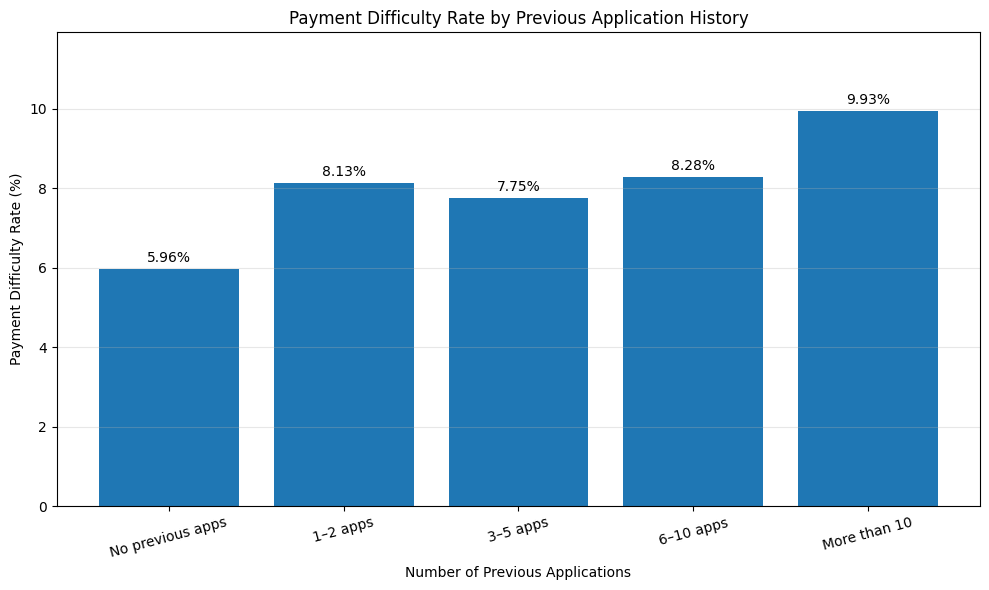

In [129]:
# Count previous applications for each applicant
prev_count = (
    prev_clean.groupby('SK_ID_CURR')['SK_ID_PREV']
    .count()
)

# Map the counts to the main applicant dataset
app_clean['PREV_APP_COUNT'] = (
    app_clean['SK_ID_CURR']
    .map(prev_count)
    .fillna(0)
)

# Group applicants by previous application count
bins = [-1, 0, 2, 5, 10, float('inf')]

labels = [
    'No previous apps',
    '1–2 apps',
    '3–5 apps',
    '6–10 apps',
    'More than 10'
]

app_clean['PREV_APP_GROUP'] = pd.cut(
    app_clean['PREV_APP_COUNT'],
    bins=bins,
    labels=labels
)

# Calculate payment difficulty rate
rates = (
    app_clean.groupby(
        'PREV_APP_GROUP',
        observed=False
    )['TARGET']
    .mean()
    .reindex(labels) * 100
)

# Plot the results
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    rates.index.astype(str),
    rates.values
)

ax.bar_label(
    bars,
    labels=[f'{v:.2f}%' for v in rates.values],
    padding=3
)

ax.set_title(
    'Payment Difficulty Rate by Previous Application History'
)
ax.set_xlabel('Number of Previous Applications')
ax.set_ylabel('Payment Difficulty Rate (%)')
ax.set_ylim(0, max(rates.values) * 1.2)
ax.tick_params(axis='x', rotation=15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(
    'rq3_previous_application_history.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


### Previous Application History vs Payment Difficulties

The analysis shows that applicants with `TARGET = 1` had a slightly higher average number of previous applications than applicants with `TARGET = 0` (4.93 compared with 4.57).

When grouped by application history, applicants with more than 10 previous applications recorded the highest payment difficulty rate at 9.93%, while applicants without previous application records had the lowest rate at 5.96%. However, the pattern was not strictly increasing across all groups.

These findings suggest an association between previous application history and payment difficulties. Further investigation is required to determine whether this relationship remains after considering other applicant characteristics. The results do not establish causation.

In [130]:
#Analysis of previous status according to TARGET
#Do applicants who previously had an application rejected show a different rate for TARGET = 1
#Calculate the number of 'Approved', 'Refused', and 'Canceled' applications for each SK_ID_CURR, then merge this summary with 'app_clean'.
prev_status_count = pd.crosstab(
    prev_clean['SK_ID_CURR'],
    prev_clean['NAME_CONTRACT_STATUS']
)

prev_status_count.head()

NAME_CONTRACT_STATUS,Approved,Canceled,Refused,Unused offer
SK_ID_CURR,,,,
100001,1,0,0,0
100002,1,0,0,0
100003,3,0,0,0
100004,1,0,0,0
100005,1,1,0,0


In [131]:
#Add application status information to app_clean
prev_status_count = prev_status_count.reset_index()

app_status = app_clean.merge(
    prev_status_count,
    on='SK_ID_CURR',
    how='left'
)

status_cols = ['Approved', 'Canceled', 'Refused', 'Unused offer']

app_status[status_cols] = app_status[status_cols].fillna(0)

In [132]:
#Compare the average number of rejected applications by TARGET
app_status.groupby('TARGET')['Refused'].agg(
    ['count', 'mean', 'median']
).round(2)

,count,mean,median
TARGET,,,
0,282686,0.76,0.0
1,24825,1.19,0.0


In [133]:
#Compare TARGET rates based on rejection history
app_status['EVER_REFUSED'] = (
    app_status['Refused'] > 0
).map({
    True: 'Had refused application',
    False: 'No refused application'
})

pd.crosstab(
    app_status['EVER_REFUSED'],
    app_status['TARGET'],
    normalize='index'
).mul(100).round(2)

TARGET,0,1
EVER_REFUSED,,
Had refused application,89.68,10.32
No refused application,93.02,6.98


### Previous Application Rejections vs Payment Difficulties

Applicants with `TARGET = 1` had a higher average number of previously refused applications than those with `TARGET = 0` (1.19 compared with 0.76).

The payment difficulty rate was 10.32% among applicants who had at least one previously refused application, compared with 6.98% among those without a refused application history. This represents a difference of 3.34 percentage points.

These findings suggest that previous application rejections are associated with a higher payment difficulty rate. However, this relationship does not establish causation, and other applicant characteristics may also contribute to the observed difference.

In [134]:
prev_amounts = prev_clean.groupby('SK_ID_CURR').agg(
    PREV_TOTAL_APPLICATION=('SK_ID_PREV', 'count'),
    PREV_AVG_CREDIT=('AMT_CREDIT', 'mean'),
    PREV_TOTAL_CREDIT=('AMT_CREDIT', 'sum')
).reset_index()

app_prev_amounts = app_clean.merge(
    prev_amounts,
    on='SK_ID_CURR',
    how='left'
)

app_prev_amounts[
    ['PREV_TOTAL_APPLICATION', 'PREV_AVG_CREDIT', 'PREV_TOTAL_CREDIT']
] = app_prev_amounts[
    ['PREV_TOTAL_APPLICATION', 'PREV_AVG_CREDIT', 'PREV_TOTAL_CREDIT']
].fillna(0)

app_prev_amounts.groupby('TARGET')[
    ['PREV_AVG_CREDIT', 'PREV_TOTAL_CREDIT']
].median().round(2)

,PREV_AVG_CREDIT,PREV_TOTAL_CREDIT
TARGET,,
0,110753.1,383503.5
1,106719.0,386527.5


### Previous Application Credit Amounts vs Payment Difficulties

The median average credit amount from previous applications was slightly higher among applicants with `TARGET = 0` (110,753.10) than among those with `TARGET = 1` (106,719.00). In contrast, the median total credit amount was slightly higher among applicants with `TARGET = 1` (386,527.50) compared with `TARGET = 0` (383,503.50).

The differences between the two groups were relatively small. Based on these median values alone, previous application credit amounts do not show a clear distinction between applicants with and without payment difficulties. Further analysis would be needed to assess their relationship with payment outcomes.

### Decision for the missing values

We have identified missing values ​​in `app_clean` and `prev_clean`, but we need to ensure that the decisions made regarding data handling are properly documented.


In [135]:
#Missing values from app_clean
app_missing = app_clean.isnull().sum()

app_missing = app_missing[app_missing > 0].sort_values(
    ascending=False
)

print("Columns with missing values:", len(app_missing))
print(app_missing.head(20))

Columns with missing values: 72
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_MODE            204488
OWN_CAR_AGE                 202929
LANDAREA_MODE               182590
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
dtype: int64


In [136]:
#Missing values from prev_clean
prev_missing = prev_clean.isnull().sum()

prev_missing = prev_missing[prev_missing > 0].sort_values(
    ascending=False
)

print("Columns with missing values:", len(prev_missing))
print(prev_missing)

Columns with missing values: 16
RATE_INTEREST_PRIVILEGED     1664263
RATE_INTEREST_PRIMARY        1664263
DAYS_FIRST_DRAWING           1607509
DAYS_TERMINATION              898978
AMT_DOWN_PAYMENT              895844
RATE_DOWN_PAYMENT             895844
DAYS_LAST_DUE                 884286
NAME_TYPE_SUITE               820405
DAYS_LAST_DUE_1ST_VERSION     766929
DAYS_FIRST_DUE                713710
NFLAG_INSURED_ON_APPROVAL     673065
AMT_GOODS_PRICE               385515
AMT_ANNUITY                   372235
CNT_PAYMENT                   372230
PRODUCT_COMBINATION              346
AMT_CREDIT                         1
dtype: int64


In [137]:
def missing_summary(df):
    result = pd.DataFrame({
        'Missing_Count': df.isnull().sum(),
        'Missing_Percentage': df.isnull().mean() * 100
    })

    result = result[result['Missing_Count'] > 0]
    return result.sort_values(
        'Missing_Percentage',
        ascending=False
    ).round(2)

app_missing_summary = missing_summary(app_clean)
prev_missing_summary = missing_summary(prev_clean)

print("APPLICATION DATA")
print(app_missing_summary)

print("\nPREVIOUS APPLICATION DATA")
print(prev_missing_summary)

APPLICATION DATA
                          Missing_Count  Missing_Percentage
COMMONAREA_MODE                  214865               69.87
COMMONAREA_MEDI                  214865               69.87
COMMONAREA_AVG                   214865               69.87
NONLIVINGAPARTMENTS_MODE         213514               69.43
NONLIVINGAPARTMENTS_AVG          213514               69.43
...                                 ...                 ...
GOODS_PRICE_GROUP                   278                0.09
ANNUITY_GROUP                        12                0.00
AMT_ANNUITY                          12                0.00
CNT_FAM_MEMBERS                       2                0.00
DAYS_LAST_PHONE_CHANGE                1                0.00

[72 rows x 2 columns]

PREVIOUS APPLICATION DATA
                           Missing_Count  Missing_Percentage
RATE_INTEREST_PRIVILEGED         1664263               99.64
RATE_INTEREST_PRIMARY            1664263               99.64
DAYS_FIRST_DRAWING            

In [138]:
outlier_check = {
    'app_clean': [
        'AMT_INCOME_TOTAL',
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'CNT_CHILDREN',
        'DAYS_EMPLOYED'
    ],
    'prev_clean': [
        'AMT_APPLICATION',
        'AMT_CREDIT',
        'AMT_ANNUITY',
        'CNT_PAYMENT',
        'SELLERPLACE_AREA'
    ]
}

for df_name, cols in outlier_check.items():
    df = globals()[df_name]

    print(f"\n{df_name}")
    print(df[cols].describe().loc[['min', '50%', 'max']].T)


app_clean
                      min       50%          max
AMT_INCOME_TOTAL  25650.0  147150.0  117000000.0
AMT_CREDIT        45000.0  513531.0    4050000.0
AMT_ANNUITY        1615.5   24903.0     258025.5
CNT_CHILDREN          0.0       0.0         19.0
DAYS_EMPLOYED    -17912.0   -1213.0     365243.0

prev_clean
                  min      50%          max
AMT_APPLICATION   0.0  71046.0  6905160.000
AMT_CREDIT        0.0  80541.0  6905160.000
AMT_ANNUITY       0.0  11250.0   418058.145
CNT_PAYMENT       0.0     12.0       84.000
SELLERPLACE_AREA -1.0      3.0  4000000.000


# 07. Top 10 Correlations by TARGET Segment

In [139]:
#top 10 correlation for TARGET 0 dan TARGET 1

numeric_df = app_clean.select_dtypes(include='number')

# Separate applicants by TARGET
target_0 = numeric_df[numeric_df['TARGET'] == 0].drop(
    columns='TARGET'
)

target_1 = numeric_df[numeric_df['TARGET'] == 1].drop(
    columns='TARGET'
)

# Correlation matrices for each segment
corr_0 = target_0.corr()
corr_1 = target_1.corr()

# Extract unique variable pairs and sort by absolute correlation
def top_correlations(corr_matrix, top_n=10):
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    result = upper.stack().reset_index()
    result.columns = ['Variable_1', 'Variable_2', 'Correlation']
    result['Abs_Correlation'] = result['Correlation'].abs()

    return result.sort_values(
        'Abs_Correlation', ascending=False
    ).head(top_n).round(4)

print("TOP 10 CORRELATIONS — TARGET 0")
display(top_correlations(corr_0, 10))

print("TOP 10 CORRELATIONS — TARGET 1")
display(top_correlations(corr_1, 10))

TOP 10 CORRELATIONS — TARGET 0


,Variable_1,Variable_2,Correlation,Abs_Correlation
818,DAYS_BIRTH,AGE_YEARS,-1.0000,1.0000
824,DAYS_EMPLOYED,FLAG_EMP_PHONE,-0.9998,0.9998
3041,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9985,0.9985
5115,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9985,0.9985
3391,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9972,0.9972
3323,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.9970,0.9970
3254,ENTRANCES_AVG,ENTRANCES_MEDI,0.9969,0.9969
3184,ELEVATORS_AVG,ELEVATORS_MEDI,0.9962,0.9962
3113,COMMONAREA_AVG,COMMONAREA_MEDI,0.9959,0.9959
3589,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.9956,0.9956


TOP 10 CORRELATIONS — TARGET 1


,Variable_1,Variable_2,Correlation,Abs_Correlation
786,DAYS_BIRTH,AGE_YEARS,-1.0000,1.0000
791,DAYS_EMPLOYED,FLAG_EMP_PHONE,-0.9997,0.9997
4817,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9983,0.9983
2722,BASEMENTAREA_AVG,BASEMENTAREA_MEDI,0.9982,0.9982
2932,COMMONAREA_AVG,COMMONAREA_MEDI,0.9981,0.9981
2863,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9981,0.9981
3448,NONLIVINGAPARTMENTS_AVG,NONLIVINGAPARTMENTS_MEDI,0.9981,0.9981
3198,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9978,0.9978
3325,LIVINGAPARTMENTS_AVG,LIVINGAPARTMENTS_MEDI,0.9977,0.9977
3133,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.9972,0.9972


In [140]:
print(
    app_clean[
        ['DAYS_EMPLOYED', 'FLAG_EMP_PHONE']
    ].corr().round(4)
)

print(
    pd.crosstab(
        app_clean['FLAG_EMP_PHONE'],
        app_clean['DAYS_EMPLOYED'].eq(365243),
        normalize='index'
    ).round(4)
)

                DAYS_EMPLOYED  FLAG_EMP_PHONE
DAYS_EMPLOYED          1.0000         -0.9998
FLAG_EMP_PHONE        -0.9998          1.0000
DAYS_EMPLOYED    False   True 
FLAG_EMP_PHONE                
0               0.0002  0.9998
1               1.0000  0.0000


In [141]:
#check the value 365243 in the DAYS_EMPLOYED and FLAG_EMP_PHONE columns
print(
    app_clean.loc[
        app_clean['DAYS_EMPLOYED'] == 365243,
        ['DAYS_EMPLOYED', 'FLAG_EMP_PHONE']
    ].head()
)

    DAYS_EMPLOYED  FLAG_EMP_PHONE
8          365243               0
11         365243               0
23         365243               0
38         365243               0
43         365243               0


In [142]:
# Convert '365243' value to NaN
app_clean['DAYS_EMPLOYED'] = (
    app_clean['DAYS_EMPLOYED'].replace(365243, np.nan)
)

In [143]:
#re-examine the correlation:
print(
    app_clean[
        ['DAYS_EMPLOYED', 'FLAG_EMP_PHONE']
    ].corr().round(4)
)

                DAYS_EMPLOYED  FLAG_EMP_PHONE
DAYS_EMPLOYED          1.0000          0.0023
FLAG_EMP_PHONE         0.0023          1.0000


The value 365243 in `DAYS_EMPLOYED` was treated as a special value and replaced with missing values before correlation analysis. Initially, `DAYS_EMPLOYED` and `FLAG_EMP_PHONE` showed an almost perfect negative correlation (-0.9998). After replacing the special value, the correlation decreased to 0.0023, indicating almost no linear relationship in the remaining observations. This demonstrates that the original correlation was largely driven by the special value rather than a strong underlying linear association.

In [144]:
#top 10 correlation for TARGET 0 dan TARGET 1

numeric_df = app_clean.select_dtypes(include='number')

# Separate applicants by TARGET
target_0 = numeric_df[numeric_df['TARGET'] == 0].drop(
    columns='TARGET'
)

target_1 = numeric_df[numeric_df['TARGET'] == 1].drop(
    columns='TARGET'
)

# Correlation matrices for each segment
corr_0 = target_0.corr()
corr_1 = target_1.corr()

# Extract unique variable pairs and sort by absolute correlation
def top_correlations(corr_matrix, top_n=10):
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    result = upper.stack().reset_index()
    result.columns = ['Variable_1', 'Variable_2', 'Correlation']
    result['Abs_Correlation'] = result['Correlation'].abs()

    return result.sort_values(
        'Abs_Correlation', ascending=False
    ).head(top_n).round(4)

print("TOP 10 CORRELATIONS — TARGET 0")
display(top_correlations(corr_0, 10))

print("TOP 10 CORRELATIONS — TARGET 1")
display(top_correlations(corr_1, 10))

TOP 10 CORRELATIONS — TARGET 0


,Variable_1,Variable_2,Correlation,Abs_Correlation
818,DAYS_BIRTH,AGE_YEARS,-1.0000,1.0000
3041,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9985,0.9985
5115,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9985,0.9985
3391,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9972,0.9972
3323,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.9970,0.9970
3254,ENTRANCES_AVG,ENTRANCES_MEDI,0.9969,0.9969
3184,ELEVATORS_AVG,ELEVATORS_MEDI,0.9962,0.9962
3113,COMMONAREA_AVG,COMMONAREA_MEDI,0.9959,0.9959
3589,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.9956,0.9956
2819,APARTMENTS_AVG,APARTMENTS_MEDI,0.9952,0.9952


TOP 10 CORRELATIONS — TARGET 1


,Variable_1,Variable_2,Correlation,Abs_Correlation
786,DAYS_BIRTH,AGE_YEARS,-1.0000,1.0000
4817,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9983,0.9983
2722,BASEMENTAREA_AVG,BASEMENTAREA_MEDI,0.9982,0.9982
2932,COMMONAREA_AVG,COMMONAREA_MEDI,0.9981,0.9981
2863,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9981,0.9981
3448,NONLIVINGAPARTMENTS_AVG,NONLIVINGAPARTMENTS_MEDI,0.9981,0.9981
3198,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.9978,0.9978
3325,LIVINGAPARTMENTS_AVG,LIVINGAPARTMENTS_MEDI,0.9977,0.9977
3133,FLOORSMAX_AVG,FLOORSMAX_MEDI,0.9972,0.9972
4183,NONLIVINGAPARTMENTS_MODE,NONLIVINGAPARTMENTS_MEDI,0.9970,0.9970


### Top 10 Correlations by Target Segment

The correlation analysis was conducted separately for applicants with no payment difficulties (TARGET = 0) and applicants with payment difficulties (TARGET = 1).

Both segments showed very high correlations between several numerical variables. For TARGET = 0, the highest correlation was 0.9985, observed between `YEARS_BUILD_AVG` and `YEARS_BUILD_MEDI`, as well as between `OBS_30_CNT_SOCIAL_CIRCLE` and `OBS_60_CNT_SOCIAL_CIRCLE`. For TARGET = 1, the highest correlation was 0.9983 between `OBS_30_CNT_SOCIAL_CIRCLE` and `OBS_60_CNT_SOCIAL_CIRCLE`.

Many of the highly correlated pairs represent different statistical measurements of similar property characteristics, such as average and median values. These results suggest that some variables contain overlapping information. The similar patterns across both target segments do not, by themselves, establish a relationship with loan repayment difficulty or imply causation.

# 08. Research Questions & Findings

# Key Findings

### 1. Target imbalance
Approximately 8.07% of applicants experienced payment difficulties (`TARGET = 1`), while 91.93% did not. This imbalance should be considered when interpreting distributions and when developing any future predictive model.


### 2. Applicant Age and Payment Difficulties

Younger applicants had higher payment difficulty rates than older applicants. The rate was 12.35% among applicants aged 20–24, compared with 3.74% among those aged 65–69. This indicates an association between applicant age and payment difficulties, with rates generally decreasing across older age groups.

### 3. External Source Scores and Payment Difficulties

Payment difficulty rates decreased consistently as external source scores increased. For `EXT_SOURCE_3`, the rate declined from 15.06% in the lowest quartile to 3.52% in the highest quartile. Similar patterns were observed for `EXT_SOURCE_1` and `EXT_SOURCE_2`. These scores showed clear associations with payment difficulty outcomes in the dataset.

### 4. Applicant characteristics

Payment difficulty rates varied across education, occupation and family-status categories. For example, the Low-skill Laborers category had a rate of 17.15%. These differences are descriptive and should be interpreted alongside category sample sizes.

### 5. Previous Application History

Applicants with more than 10 previous applications had a payment difficulty rate of 9.93%, compared with 5.96% among applicants with no previous applications recorded. Applicants with at least one previously refused application also had a higher payment difficulty rate (10.32%) than those without a refused application (6.98%). These patterns suggest that previous application history may provide useful information for further risk assessment.

### 6. Differences Across Applicant Characteristics

Payment difficulty rates varied across applicant characteristics. For example, applicants in the lower secondary education category had a rate of 10.93%, compared with 5.36% among applicants with higher education. However, these are observational comparisons and do not establish that education level causes payment difficulties.

### 7. Data Quality and Correlation Patterns

The analysis identified missing values, unusual numerical values, and highly correlated variables. After the special value `365243` was replaced with a missing value in `DAYS_EMPLOYED`, its correlation with `FLAG_EMP_PHONE` changed substantially. This highlights the importance of data cleaning before interpreting statistical relationships.

# 09. Business Recommendations & Conclusion

## Recommendations for Credit Risk Assessment

### 1. Review Age-Related Risk Patterns

Younger applicants showed higher payment difficulty rates. Age may be considered alongside other relevant financial and applicant characteristics during further risk analysis.

### 2. Evaluate External Source Scores

The company could assess whether external source scores provide useful additional information for credit risk assessment. Their predictive value, data coverage, fairness, and suitability should be validated before they are incorporated into decision-making processes.

### 3. Incorporate Previous Application History for Further Assessment

The company could investigate whether previous application counts and refusal history improve risk assessment when combined with other applicant information. These indicators should be validated and should not be treated as automatic grounds for rejection.

### 4. Multiple indicators

Credit risk assessment should consider several relevant variables together rather than relying on a single characteristic. Further statistical analysis and predictive modelling are needed before using these findings to support lending decisions.

## Limitations

### 1. Exploratory analysis only

The analysis identifies patterns and associations but does not establish causal relationships.

### 2. Class imbalance

Only 8.07% of applicants experienced payment difficulties, compared with 91.93% who did not. This imbalance should be considered when interpreting results and developing predictive models.

### 3. Missing data

Several variables contain substantial amounts of missing data, which may affect the analysis and limit the number of observations available for certain comparisons.

### 4. Potential outliers and special values

Some extreme or unusual values may influence summary statistics and correlation results, even after data quality checks.

### 5. Correlation limitations

Correlation measures may not capture all types of relationships and should not be interpreted as evidence of causation.

### 6. No predictive model validation

This project does not establish whether the identified variables can accurately predict future payment difficulties. Further modelling and validation are required.

## Data Quality Improvements

### 1. Improve Data Quality and Documentation

The data team should document the treatment of missing values and special values, investigate unusual numerical observations, and review highly correlated variables. These steps can improve the reliability and interpretability of future analyses.

### 2. Validate Findings Before Operational Use

The company should conduct further statistical analysis and predictive model validation before using these findings in actual lending decisions. The current EDA identifies associations and patterns but does not establish causation or prove predictive performance.

## Conclusion

The EDA identified several patterns associated with payment difficulties, particularly applicant age, external source scores and previous application rejection history. These findings can guide further investigation into applicant risk characteristics. However, no single variable should be treated as a definitive indicator of default risk without additional validation and consideration of other factors.